In [2]:
import pandas as pd
import numpy as np
import random
import matplotlib.pyplot as plt
import seaborn as sns
import math
from scipy import stats
import re


Az adathalmazok beolvasása. A fileokban amikben tároltam őket a következő oszlopok szerepelnek:


*   **dataset** : a használt dataset (adult, cifar, imdb)
*   **partition** : iid or noniid (dirichlet) particionálás
*   **num_clients** : a kliensek száma 4/20
*   **seed** : a random seed amin a kisérlet futott (42 / 107 / 123 / 2025 / 9928 )
*   **round** : az aktuális kör száma (max 10)
*   **client_id** : a kliens száma (0..3 / 0..19)
*   **global_robustness** : az adott kör aggregált robustness scoreja
*   **contribution**: az egyes kliensek kontribuciója a globális robusztussághoz, l1o-val számítva. Pozitív érték esetén pozitív a kontribució.
*   **accuracy**: A modell pontossága (helyes előrejelzések aránya).
*   **precision**: A pozitív előrejelzések közül mennyi volt valóban helyes.
*   **recall**: A valódi pozitív esetek közül mennyit ismert fel helyesen a modell.
*   **f1**: A precision és recall harmonikus átlaga (kiegyensúlyozott teljesítménymutató).
*   **loss**: A veszteségfüggvény értéke, amely a modell teljesítményének hibáját jelzi.






In [3]:
adult_data = pd.read_csv("robustness_results_adult.csv")
adultnoniid_data = pd.read_csv("robustness_results_adultnoniid.csv")
cifar_data = pd.read_csv("robustness_results_cifar.csv")
cifarnoniid_data = pd.read_csv("robustness_results_cifarnoniid.csv")
imdb_data = pd.read_csv("robustness_results_imdb.csv")
imdbnoniid_data = pd.read_csv("robustness_results_imdbnoniid.csv")

df = pd.concat([adult_data, adultnoniid_data, cifar_data, cifarnoniid_data, imdb_data, imdbnoniid_data])




In [4]:
adult_4 = adult_data[adult_data["num_clients"] == 4]
adult_20 = adult_data[adult_data["num_clients"] == 20]

adultnoniid_4 = adultnoniid_data[adultnoniid_data["num_clients"] == 4]
adultnoniid_20 = adultnoniid_data[adultnoniid_data["num_clients"] == 20]

adult_all_4 = pd.concat([adult_4, adultnoniid_4])
adult_all_20 = pd.concat([adult_20, adultnoniid_20])

adult_all = pd.concat([adult_data, adultnoniid_data])

cifar_4 = cifar_data[cifar_data["num_clients"] == 4]
cifar_20 = cifar_data[cifar_data["num_clients"] == 20]

cifarnoniid_4 = cifarnoniid_data[cifarnoniid_data["num_clients"] == 4]
cifarnoniid_20 = cifarnoniid_data[cifarnoniid_data["num_clients"] == 20]

cifar_all_4 = pd.concat([cifar_4, cifarnoniid_4])
cifar_all_20 = pd.concat([cifar_20, cifarnoniid_20])

cifar_all = pd.concat([cifar_data, cifarnoniid_data])

imdb_4 = imdb_data[imdb_data["num_clients"] == 4]
imdb_20 = imdb_data[imdb_data["num_clients"] == 20]

imdbnoniid_4 = imdbnoniid_data[imdbnoniid_data["num_clients"] == 4]
imdbnoniid_20 = imdbnoniid_data[imdbnoniid_data["num_clients"] == 20]

imdb_all_4 = pd.concat([imdb_4, imdbnoniid_4])
imdb_all_20 = pd.concat([imdb_20, imdbnoniid_20])

imdb_all = pd.concat([imdb_data, imdbnoniid_data])


In [ ]:
#printing out global robustness numbers
data_p_a = adult_all.groupby(['partition', 'num_clients', 'round'])[['global_robustness', 'accuracy']].mean().reset_index()
print("Adult")
print(data_p_a)

data_p_c = cifar_all.groupby(['partition', 'num_clients', 'round'])[['global_robustness', 'accuracy']].mean().reset_index()
print("Cifar")
print(data_p_c)

data_p_i = imdb_all.groupby(['partition', 'num_clients', 'round'])[['global_robustness', 'accuracy']].mean().reset_index()
print("Imdb")
print(data_p_i)


Adult
   partition  num_clients  round  global_robustness  accuracy
0        iid            4      1           0.996988  0.792916
1        iid            4      2           0.993798  0.803317
2        iid            4      3           0.990722  0.813226
3        iid            4      4           0.988348  0.818651
4        iid            4      5           0.988147  0.819695
5        iid            4      6           0.987840  0.820268
6        iid            4      7           0.986671  0.823401
7        iid            4      8           0.986883  0.824240
8        iid            4      9           0.986436  0.824670
9        iid            4     10           0.985903  0.825223
10       iid           20      1           0.995939  0.791115
11       iid           20      2           0.998354  0.785751
12       iid           20      3           0.998379  0.785689
13       iid           20      4           0.998336  0.787901
14       iid           20      5           0.997786  0.791524
15

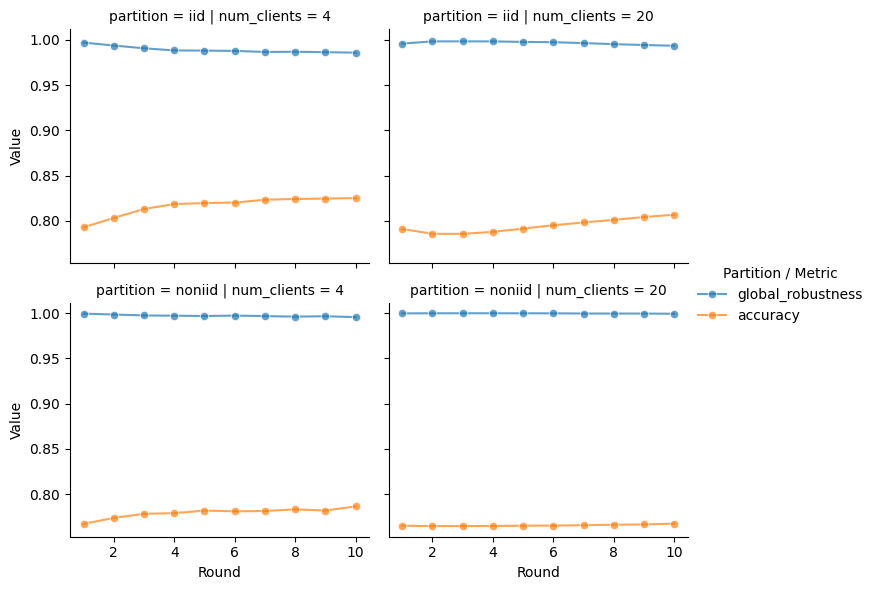

In [38]:
data = adult_all.groupby(['partition', 'num_clients', 'round'])[['global_robustness', 'accuracy']].mean().reset_index()

melted = data.melt(
    id_vars=['partition', 'num_clients', 'round'],
    value_vars=['global_robustness', 'accuracy'],
    var_name='metric',
    value_name='value'
)
g = sns.FacetGrid(
    melted,
    col="num_clients",
    row="partition",
    hue="metric",
    height=3,
    aspect=1.2
)

g.map_dataframe(
    sns.lineplot,
    x="round",
    y="value",
    marker="o",
    alpha=0.7
)

g.set_axis_labels("Round", "Value")
g.add_legend(title="Partition / Metric")
#g.fig.suptitle("Robustness and Accuracy Over Rounds - adult", y=1.05)
plt.show()


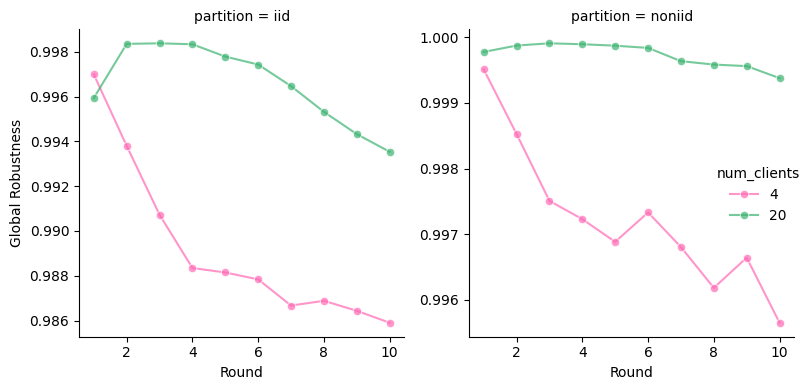

In [39]:
data = adult_all.groupby(['dataset', 'partition', 'num_clients', 'round'])['global_robustness'].mean().reset_index()
g = sns.FacetGrid(
    data,
    col='partition',
    hue='num_clients',
    height=4,
    aspect=0.9,
    sharey=False,
    palette=['hotpink', 'mediumseagreen']
)
g.map(sns.lineplot, 'round', 'global_robustness', marker='o', alpha=0.7)
g.add_legend()
g.set_axis_labels("Round", "Global Robustness")
#g.fig.suptitle("Robustness Progression by Partition and Client Count in the adult dataset", y=1.02)
plt.tight_layout()
plt.show()


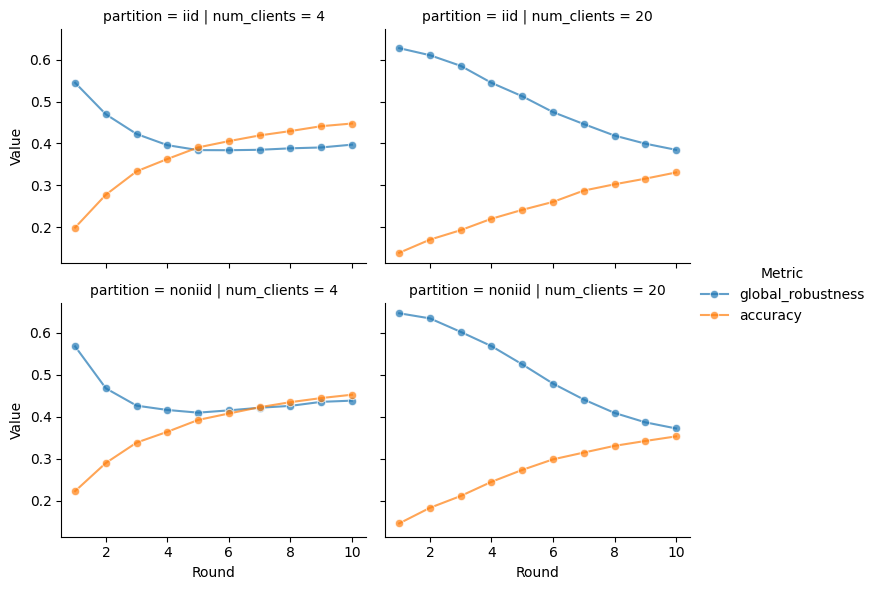

In [44]:
data = cifar_all.groupby(['partition', 'num_clients', 'round'])[['global_robustness', 'accuracy']].mean().reset_index()

melted = data.melt(
    id_vars=['partition', 'num_clients', 'round'],
    value_vars=['global_robustness', 'accuracy'],
    var_name='metric',
    value_name='value'
)
g = sns.FacetGrid(
    melted,
    col="num_clients",
    row="partition",
    hue="metric",
    height=3,
    aspect=1.2
)

g.map_dataframe(
    sns.lineplot,
    x="round",
    y="value",
    marker="o",
    alpha=0.7
)

g.set_axis_labels("Round", "Value")
g.add_legend(title="Metric")
#g.fig.suptitle("Robustness and Accuracy Over Rounds - cifar", y=1.05)
plt.show()

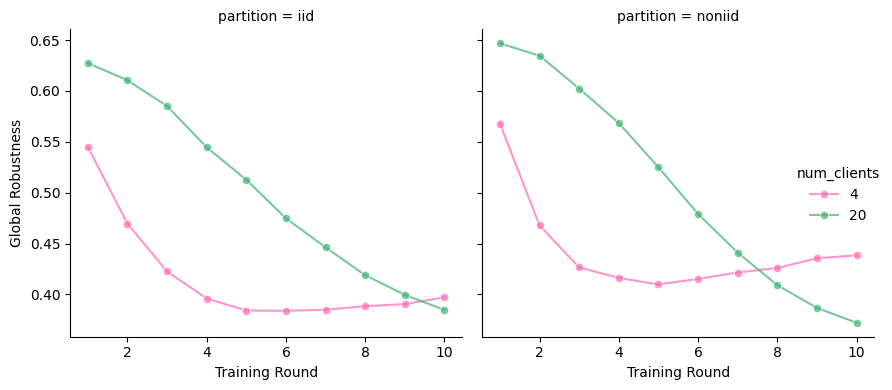

In [41]:
data = cifar_all.groupby(['dataset', 'partition', 'num_clients', 'round'])['global_robustness'].mean().reset_index()
g = sns.FacetGrid(
    data,
    col='partition',
    hue='num_clients',
    height=4,
    sharey=True,
    palette=['hotpink', 'mediumseagreen']
)
g.map(sns.lineplot, 'round', 'global_robustness', marker='o', alpha=0.7)
g.add_legend()
g.set_axis_labels("Training Round", "Global Robustness")
#g.fig.suptitle("Robustness Progression by Partition and Client Count in the cifar dataset", y=1.02)
plt.tight_layout()
plt.show()

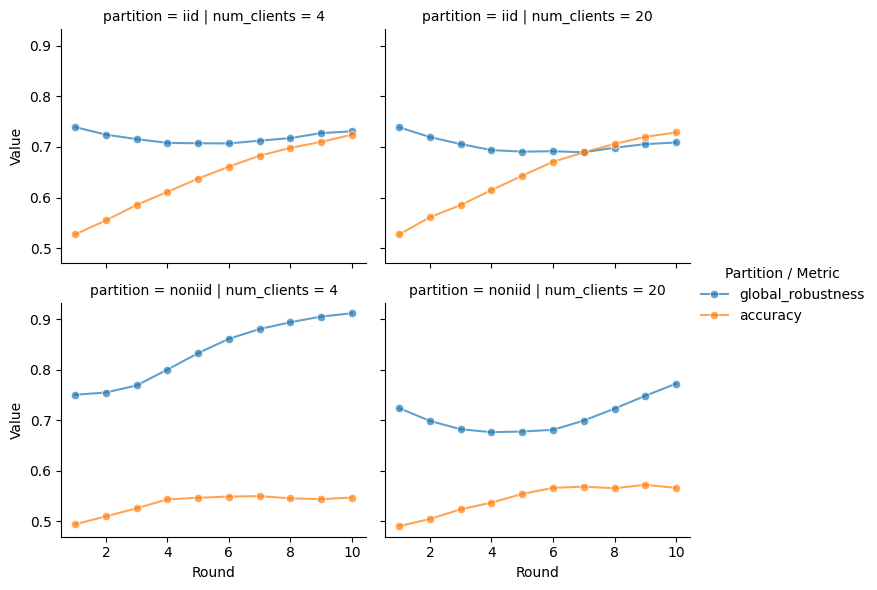

In [6]:
data = imdb_all.groupby(['partition', 'num_clients', 'round'])[['global_robustness', 'accuracy']].mean().reset_index()

melted = data.melt(
    id_vars=['partition', 'num_clients', 'round'],
    value_vars=['global_robustness', 'accuracy'],
    var_name='metric',
    value_name='value'
)
g = sns.FacetGrid(
    melted,
    col="num_clients",
    row="partition",
    hue="metric",
    height=3,
    aspect=1.2
)

g.map_dataframe(
    sns.lineplot,
    x="round",
    y="value",
    marker="o",
    alpha=0.7
)

g.set_axis_labels("Round", "Value")
g.add_legend(title="Partition / Metric")
#g.fig.suptitle("Robustness and Accuracy Over Rounds - imdb", y=1.05)
plt.show()

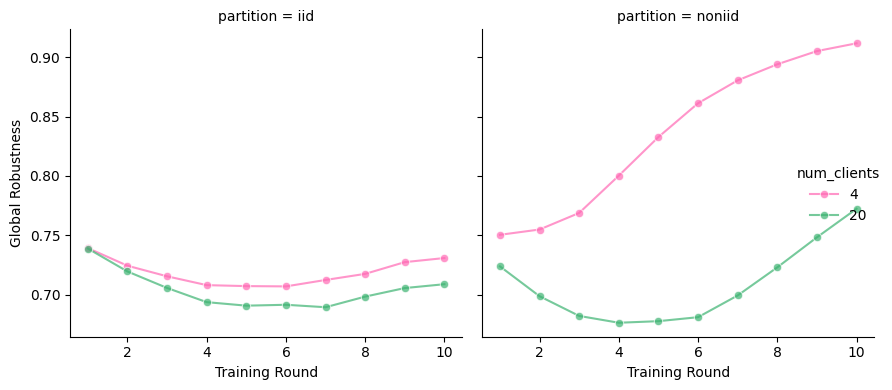

In [43]:
data = imdb_all.groupby(['dataset', 'partition', 'num_clients', 'round'])['global_robustness'].mean().reset_index()
g = sns.FacetGrid(
    data,
    col='partition',
    hue='num_clients',
    height=4,
    sharey=True,
    palette=['hotpink', 'mediumseagreen']
)
g.map(sns.lineplot, 'round', 'global_robustness', marker='o', alpha=0.7)
g.add_legend()
g.set_axis_labels("Training Round", "Global Robustness")
#g.fig.suptitle("Robustness Progression by Partition and Client Count in the imdb dataset", y=1.02)
plt.tight_layout()
plt.show()

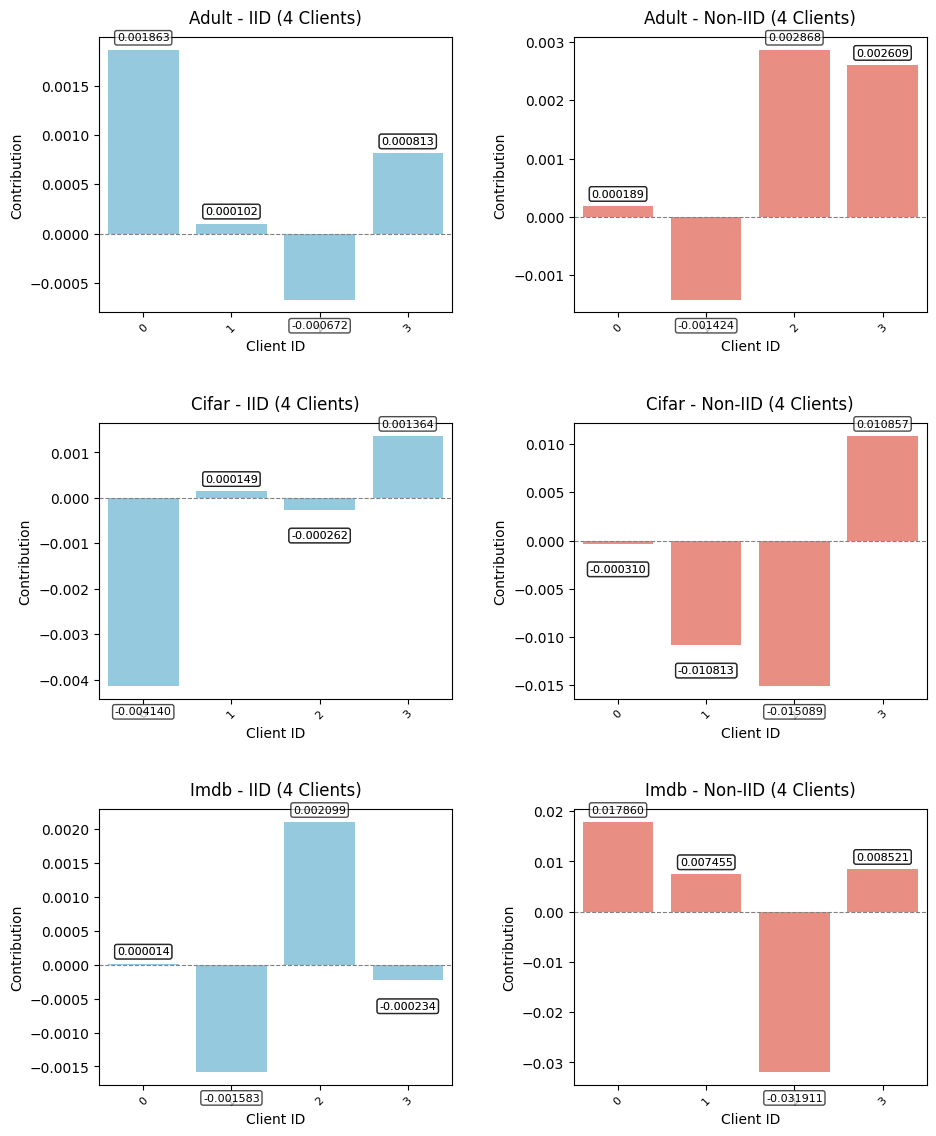

In [ ]:
# Prepare 4-client data and unstack
def prepare_data(dta):
    #df_filtered = dta[dta['round'] != 1]
    return dta.groupby(['dataset', 'partition', 'num_clients', 'client_id'])['contribution'].mean().unstack()

a_4 = prepare_data(adult_4)
an_4 = prepare_data(adultnoniid_4)
c_4 = prepare_data(cifar_4)
cn_4 = prepare_data(cifarnoniid_4)
i_4 = prepare_data(imdb_4)
in_4 = prepare_data(imdbnoniid_4)

# Create 3x2 subplot (3 datasets × 2 partitions)
fig, axes = plt.subplots(3, 2, figsize=(10, 12), sharex=False)

# Color palette
palette = {'IID': 'skyblue', 'Non-IID': 'salmon'}

# Data for plotting
plot_data = {
    ('adult', 'IID'): a_4,
    ('adult', 'Non-IID'): an_4,
    ('cifar', 'IID'): c_4,
    ('cifar', 'Non-IID'): cn_4,
    ('imdb', 'IID'): i_4,
    ('imdb', 'Non-IID'): in_4,
}

# Iterate through datasets and partitions to create plots
datasets = ['adult', 'cifar', 'imdb']
partitions = ['IID', 'Non-IID']

for i, dataset in enumerate(datasets):
    for j, partition in enumerate(partitions):
        ax = axes[i, j]
        data = plot_data[(dataset, partition)]
        df_melted = data.melt(var_name='client_id', value_name='contribution')
        sns.barplot(
            data=df_melted,
            x='client_id',
            y='contribution',
            color=palette[partition],
            ax=ax,
            width=0.8
        )
        ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
        ax.set_title(f"{dataset.capitalize()} - {partition} (4 Clients)", pad=10, fontsize=12)
        ax.set_ylabel("Contribution", fontsize=10)
        ax.set_xlabel("Client ID", fontsize=10)
        ax.tick_params(axis='x', rotation=45, labelsize=8)

        # Add value labels to top/bottom contributors
        bars = sorted(ax.patches, key=lambda p: p.get_height())
        for p in bars[:3] + bars[-3:]:  # Label extremes only
            ax.annotate(
                f"{p.get_height():.6f}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center',
                va='bottom' if p.get_height() >= 0 else 'top',
                xytext=(0, 5 if p.get_height() >= 0 else -15),
                textcoords='offset points',
                fontsize=8,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7)
            )

plt.tight_layout(pad=3.0)
plt.show()

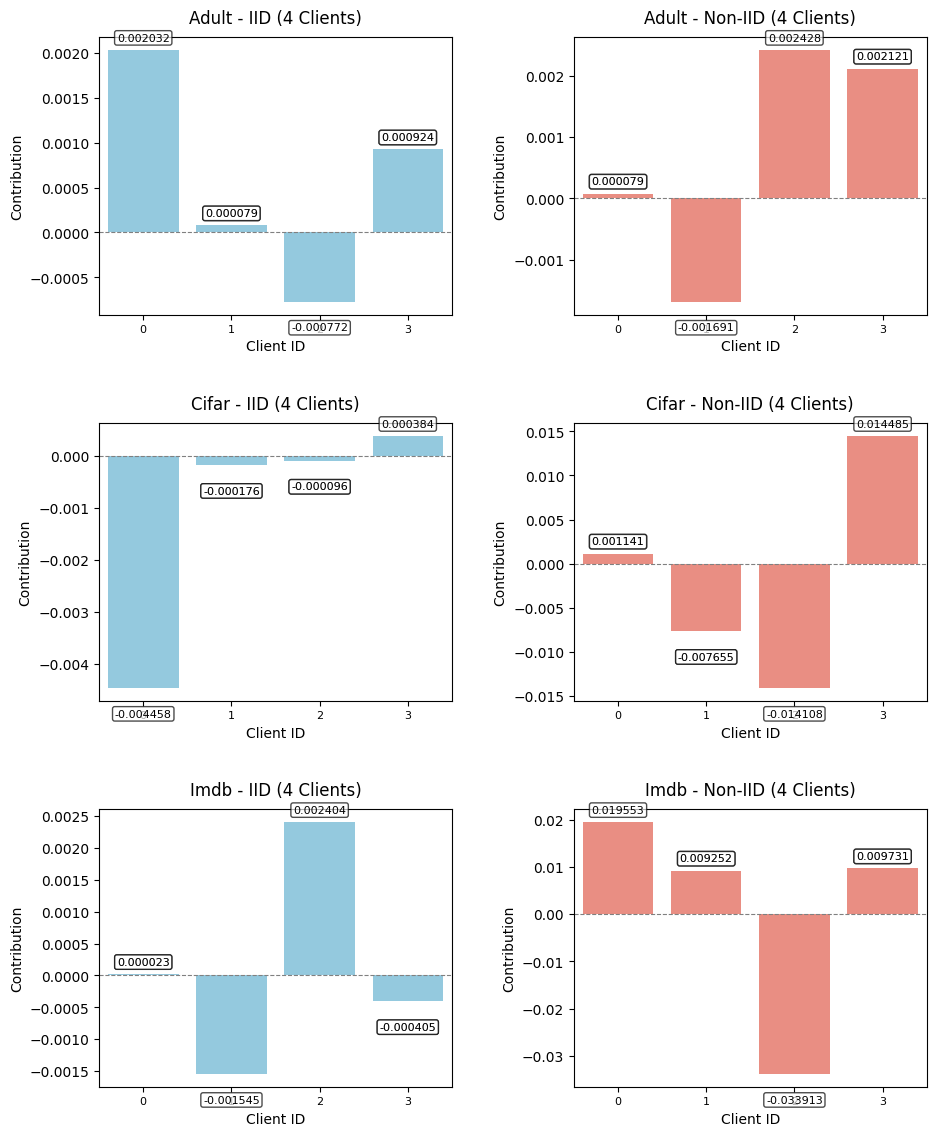

In [ ]:
# Prepare 4-client data and unstack
def prepare_data(dta):
    df_filtered = dta[dta['round'] != 1]
    return df_filtered.groupby(['dataset', 'partition', 'num_clients', 'client_id'])['contribution'].mean().unstack()

a_4 = prepare_data(adult_4)
an_4 = prepare_data(adultnoniid_4)
c_4 = prepare_data(cifar_4)
cn_4 = prepare_data(cifarnoniid_4)
i_4 = prepare_data(imdb_4)
in_4 = prepare_data(imdbnoniid_4)

# Create 3x2 subplot (3 datasets × 2 partitions)
fig, axes = plt.subplots(3, 2, figsize=(10, 12), sharex=False)

# Color palette
palette = {'IID': 'skyblue', 'Non-IID': 'salmon'}

# Data for plotting
plot_data = {
    ('adult', 'IID'): a_4,
    ('adult', 'Non-IID'): an_4,
    ('cifar', 'IID'): c_4,
    ('cifar', 'Non-IID'): cn_4,
    ('imdb', 'IID'): i_4,
    ('imdb', 'Non-IID'): in_4,
}

# Iterate through datasets and partitions to create plots
datasets = ['adult', 'cifar', 'imdb']
partitions = ['IID', 'Non-IID']

for i, dataset in enumerate(datasets):
    for j, partition in enumerate(partitions):
        ax = axes[i, j]
        data = plot_data[(dataset, partition)]
        df_melted = data.melt(var_name='client_id', value_name='contribution')
        sns.barplot(
            data=df_melted,
            x='client_id',
            y='contribution',
            color=palette[partition],
            ax=ax,
            width=0.8
        )
        ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
        ax.set_title(f"{dataset.capitalize()} - {partition} (4 Clients)", pad=10, fontsize=12)
        ax.set_ylabel("Contribution", fontsize=10)
        ax.set_xlabel("Client ID", fontsize=10)
        ax.tick_params(axis='x', labelsize=8)

        # Add value labels to top/bottom contributors
        bars = sorted(ax.patches, key=lambda p: p.get_height())
        for p in bars[:3] + bars[-3:]:  # Label extremes only
            ax.annotate(
                f"{p.get_height():.6f}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center',
                va='bottom' if p.get_height() >= 0 else 'top',
                xytext=(0, 5 if p.get_height() >= 0 else -15),
                textcoords='offset points',
                fontsize=8,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7)
            )

plt.tight_layout(pad=3.0)
plt.show()

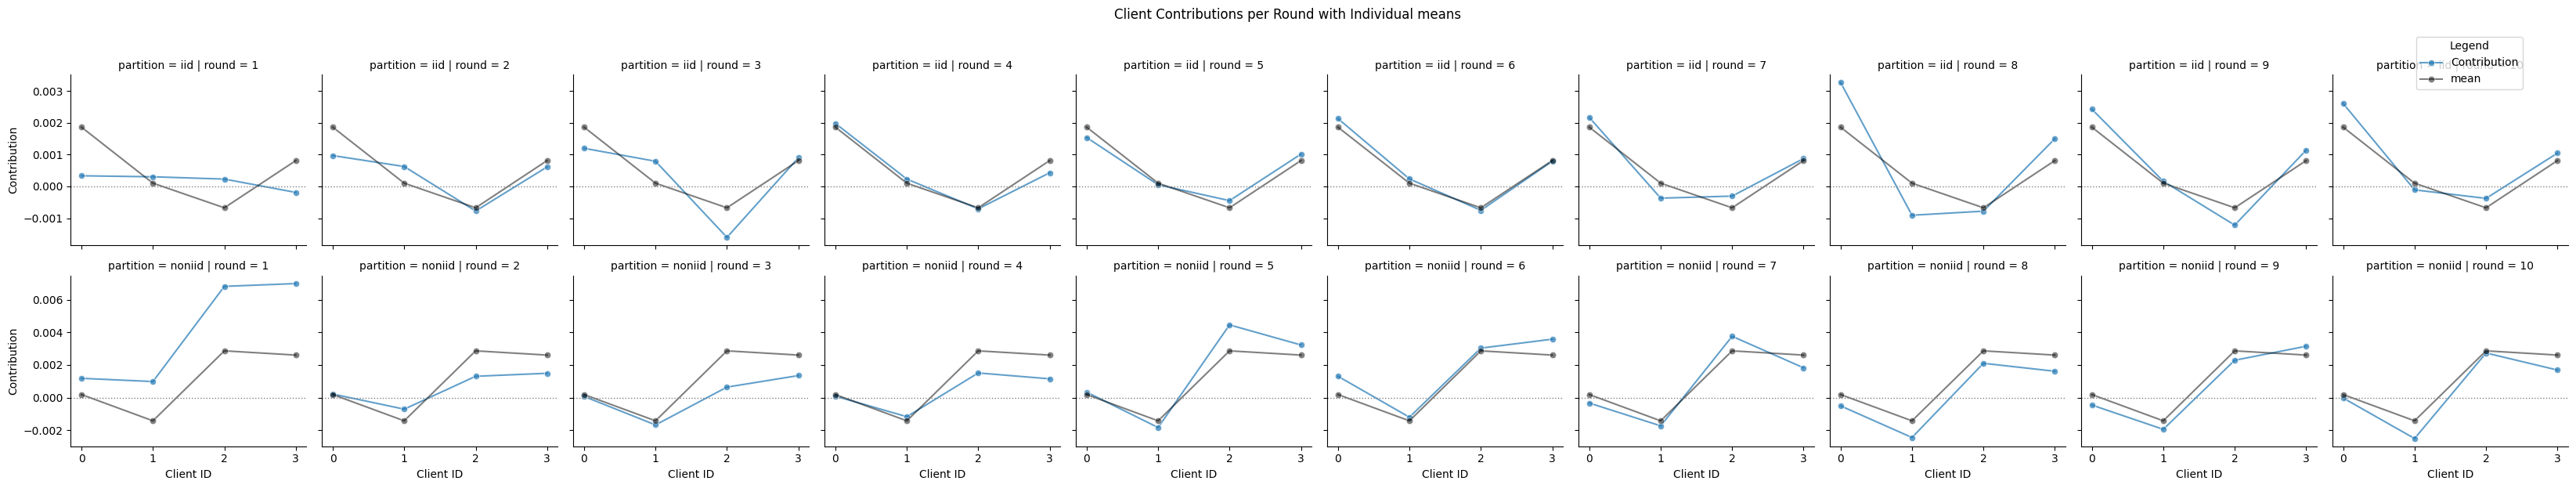

In [ ]:
data = adult_all_4.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()

mean_contrib = adult_all_4.groupby(['partition', 'client_id'])['contribution'].mean().reset_index()
mean_contrib.rename(columns={'contribution': 'mean_contribution'}, inplace=True)

data['client_id'] = data['client_id'].astype(str)
mean_contrib['client_id'] = mean_contrib['client_id'].astype(str)


def plot_contribution_with_mean(x, y, **kwargs): # Changed the function signature to accept x and y arguments
    # Get the current facet's data subset

    df = kwargs.pop('data')
    curr_partition = df['partition'].iloc[0]
    mean_subset = mean_contrib[mean_contrib['partition'] == curr_partition]

    df = df.merge(mean_subset, on=['client_id', 'partition'], how='left')

    # Plot actual contributions
    sns.lineplot(data=df, x=x, y=y, marker='o', alpha=0.7, label='Contribution') #Use x and y to specify columns
    # Plot mean
    sns.lineplot(data=df, x=x, y='mean_contribution', marker='o', color='black', alpha=0.5, label='mean')

    plt.axhline(y=0, color='gray', linestyle=':', linewidth=1)


g = sns.FacetGrid(
    data,
    row='partition',
    col='round',
    height=3,
    aspect=1.1,
    sharey='row',
)

g.map_dataframe(plot_contribution_with_mean, 'client_id', 'contribution') # Added 'client_id' and 'contribution' as arguments

# Axis labels and title
g.set_axis_labels("Client ID", "Contribution")
g.fig.suptitle("Client Contributions per Round with Individual means", y=1.03)

# Add a shared legend (from one subplot)
handles, labels = g.axes[0][0].get_legend_handles_labels()
g.fig.legend(handles=handles, labels=labels, title='Legend', loc='upper right', bbox_to_anchor=(0.98, 0.98))

plt.tight_layout()
plt.show()

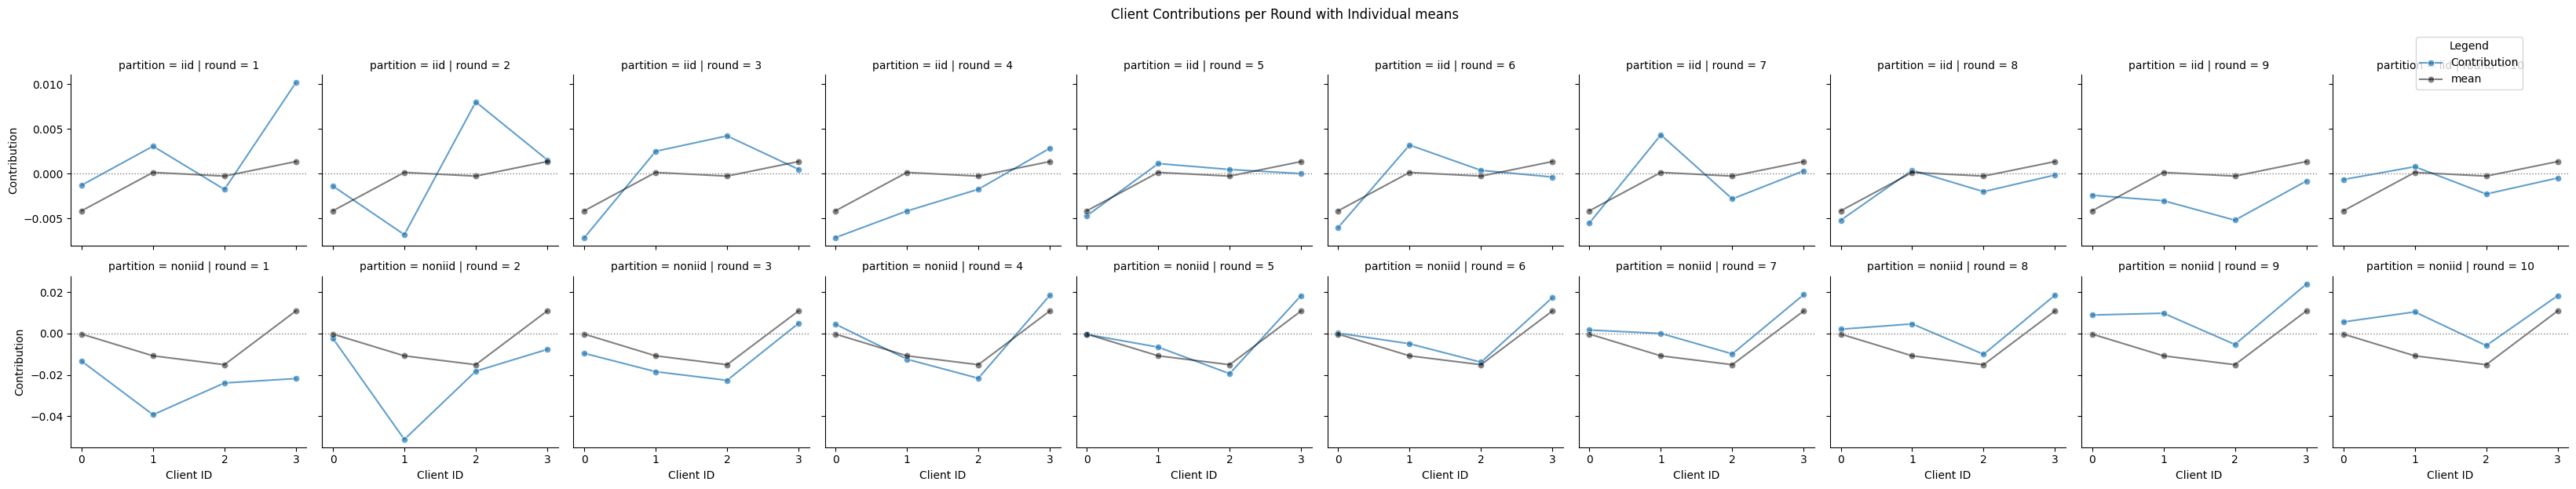

In [ ]:
data = cifar_all_4.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()

mean_contrib = cifar_all_4.groupby(['partition', 'client_id'])['contribution'].mean().reset_index()
mean_contrib.rename(columns={'contribution': 'mean_contribution'}, inplace=True)

data['client_id'] = data['client_id'].astype(str)
mean_contrib['client_id'] = mean_contrib['client_id'].astype(str)


def plot_contribution_with_mean(x, y, **kwargs):
    # Get the current facet's data subset

    df = kwargs.pop('data')
    curr_partition = df['partition'].iloc[0]
    mean_subset = mean_contrib[mean_contrib['partition'] == curr_partition]

    df = df.merge(mean_subset, on=['client_id', 'partition'], how='left')

    # Plot actual contributions
    sns.lineplot(data=df, x=x, y=y, marker='o', alpha=0.7, label='Contribution')
    # Plot mean
    sns.lineplot(data=df, x=x, y='mean_contribution', marker='o', color='black', alpha=0.5, label='mean')

    plt.axhline(y=0, color='gray', linestyle=':', linewidth=1)


g = sns.FacetGrid(
    data,
    row='partition',
    col='round',
    height=3,
    aspect=1.1,
    sharey='row',
)

g.map_dataframe(plot_contribution_with_mean, 'client_id', 'contribution')

# Axis labels and title
g.set_axis_labels("Client ID", "Contribution")
g.fig.suptitle("Client Contributions per Round with Individual means", y=1.03)

# Add a shared legend (from one subplot)
handles, labels = g.axes[0][0].get_legend_handles_labels()
g.fig.legend(handles=handles, labels=labels, title='Legend', loc='upper right', bbox_to_anchor=(0.98, 0.98))

plt.tight_layout()
plt.show()

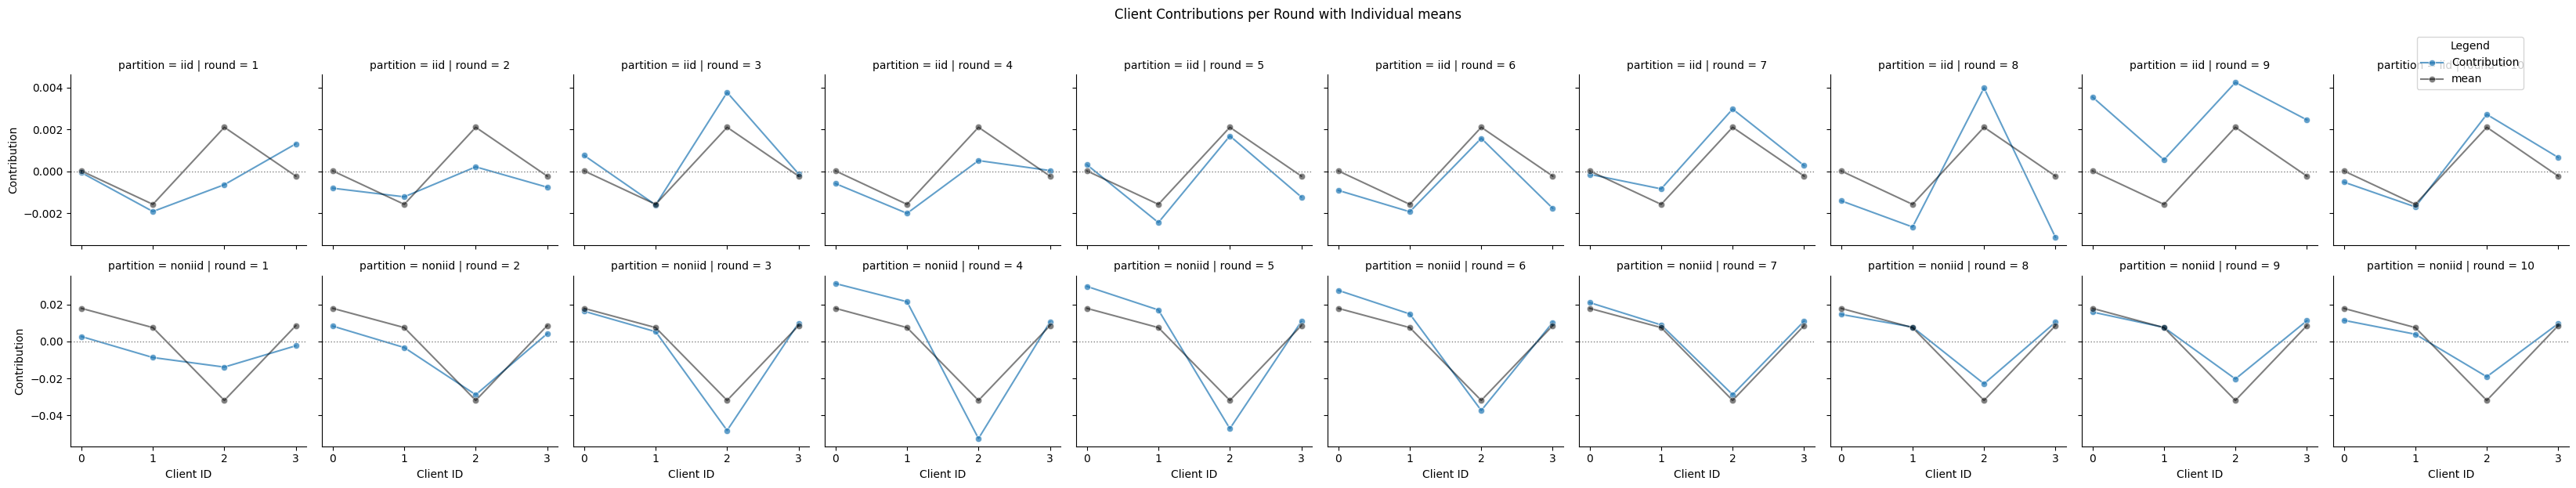

In [ ]:
data = imdb_all_4.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()

mean_contrib = imdb_all_4.groupby(['partition', 'client_id'])['contribution'].mean().reset_index()
mean_contrib.rename(columns={'contribution': 'mean_contribution'}, inplace=True)

data['client_id'] = data['client_id'].astype(str)
mean_contrib['client_id'] = mean_contrib['client_id'].astype(str)


def plot_contribution_with_mean(x, y, **kwargs): # Changed the function signature to accept x and y arguments
    # Get the current facet's data subset

    df = kwargs.pop('data')
    curr_partition = df['partition'].iloc[0]
    mean_subset = mean_contrib[mean_contrib['partition'] == curr_partition]

    df = df.merge(mean_subset, on=['client_id', 'partition'], how='left')

    # Plot actual contributions
    sns.lineplot(data=df, x=x, y=y, marker='o', alpha=0.7, label='Contribution') #Use x and y to specify columns
    # Plot mean
    sns.lineplot(data=df, x=x, y='mean_contribution', marker='o', color='black', alpha=0.5, label='mean')

    plt.axhline(y=0, color='gray', linestyle=':', linewidth=1)


g = sns.FacetGrid(
    data,
    row='partition',
    col='round',
    height=3,
    aspect=1.1,
    sharey='row',
)

g.map_dataframe(plot_contribution_with_mean, 'client_id', 'contribution') # Added 'client_id' and 'contribution' as arguments

# Axis labels and title
g.set_axis_labels("Client ID", "Contribution")
g.fig.suptitle("Client Contributions per Round with Individual means", y=1.03)

# Add a shared legend (from one subplot)
handles, labels = g.axes[0][0].get_legend_handles_labels()
g.fig.legend(handles=handles, labels=labels, title='Legend', loc='upper right', bbox_to_anchor=(0.98, 0.98))

plt.tight_layout()
plt.show()

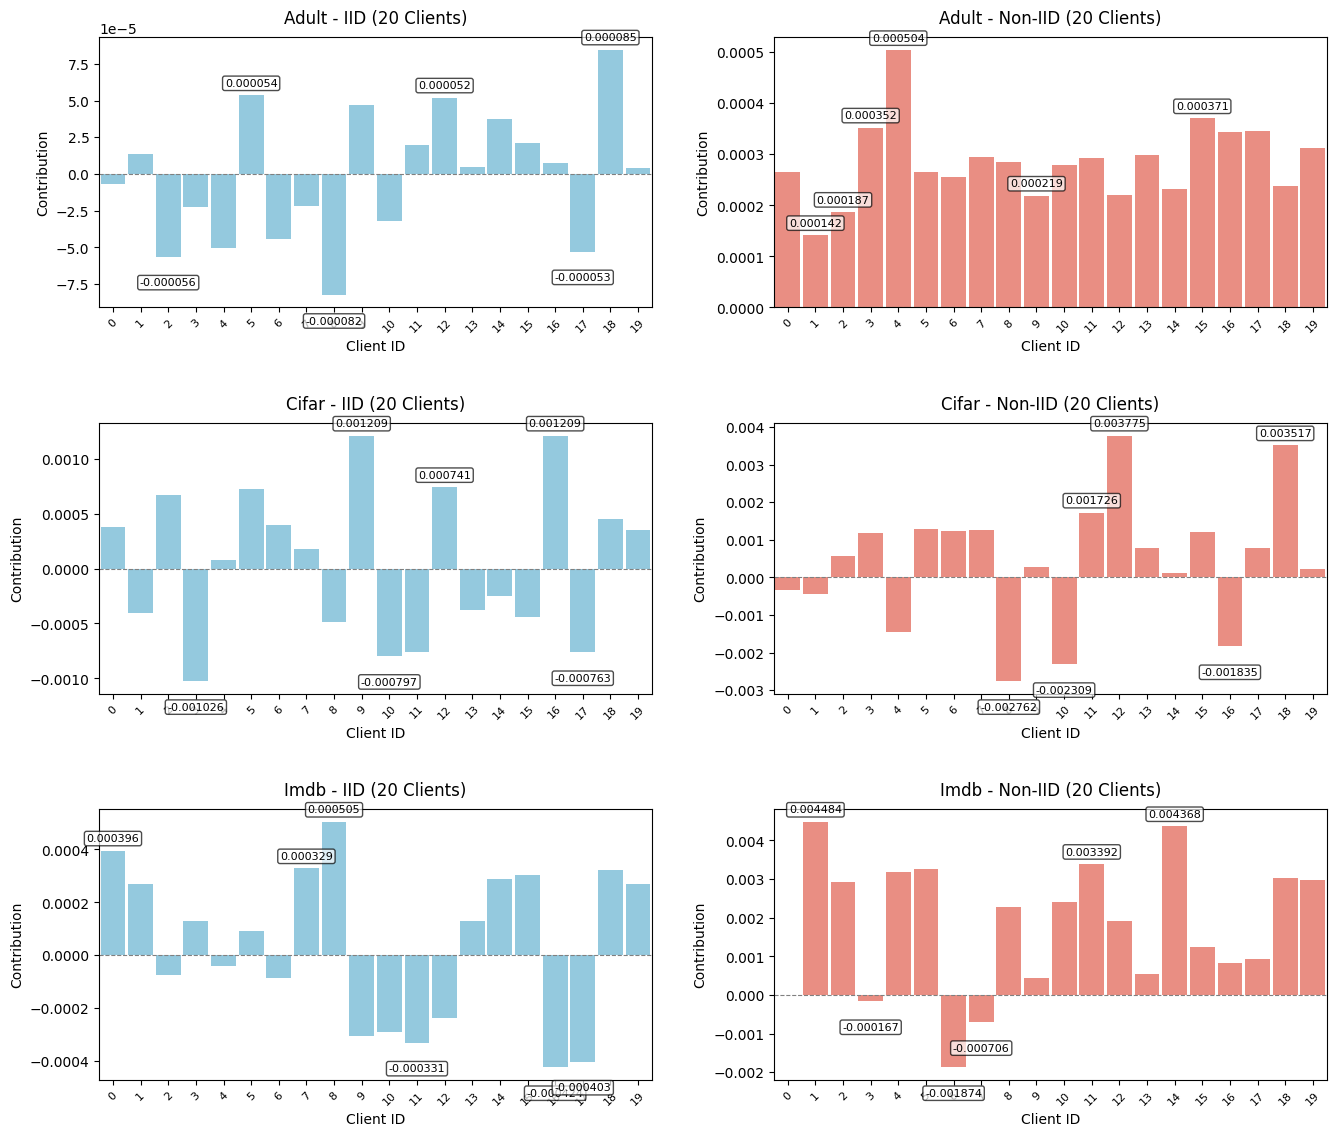

In [ ]:
# Prepare 20-client data and unstack
def prepare_data(dta):
    #dta = dta[dta['round'] != 1]
    return dta.groupby(['dataset', 'partition', 'num_clients', 'client_id'])['contribution'].mean().unstack()

a_20 = prepare_data(adult_20)
an_20 = prepare_data(adultnoniid_20)
c_20 = prepare_data(cifar_20)
cn_20 = prepare_data(cifarnoniid_20)
i_20 = prepare_data(imdb_20)
in_20 = prepare_data(imdbnoniid_20)

# Create 3x2 subplot (3 datasets × 2 partitions)
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=False)

# Color palette
palette = {'IID': 'skyblue', 'Non-IID': 'salmon'}

# Data for plotting
plot_data = {
    ('adult', 'IID'): a_20,
    ('adult', 'Non-IID'): an_20,
    ('cifar', 'IID'): c_20,
    ('cifar', 'Non-IID'): cn_20,
    ('imdb', 'IID'): i_20,
    ('imdb', 'Non-IID'): in_20,
}

# Iterate through datasets and partitions to create plots
datasets = ['adult', 'cifar', 'imdb']
partitions = ['IID', 'Non-IID']

for i, dataset in enumerate(datasets):
    for j, partition in enumerate(partitions):
        ax = axes[i, j]
        data = plot_data[(dataset, partition)]
        df_melted = data.melt(var_name='client_id', value_name='contribution')
        sns.barplot(
            data=df_melted,
            x='client_id',
            y='contribution',
            color=palette[partition],
            ax=ax,
            width=0.9
        )
        ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
        ax.set_title(f"{dataset.capitalize()} - {partition} (20 Clients)", pad=10, fontsize=12)
        ax.set_ylabel("Contribution", fontsize=10)
        ax.set_xlabel("Client ID", fontsize=10)
        ax.tick_params(axis='x', rotation=45, labelsize=8)

        # Add value labels to top/bottom contributors
        bars = sorted(ax.patches, key=lambda p: p.get_height())
        for p in bars[:3] + bars[-3:]:  # Label extremes only
            ax.annotate(
                f"{p.get_height():.6f}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center',
                va='bottom' if p.get_height() >= 0 else 'top',
                xytext=(0, 5 if p.get_height() >= 0 else -15),
                textcoords='offset points',
                fontsize=8,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7)
            )

plt.tight_layout(pad=3.0)
plt.show()

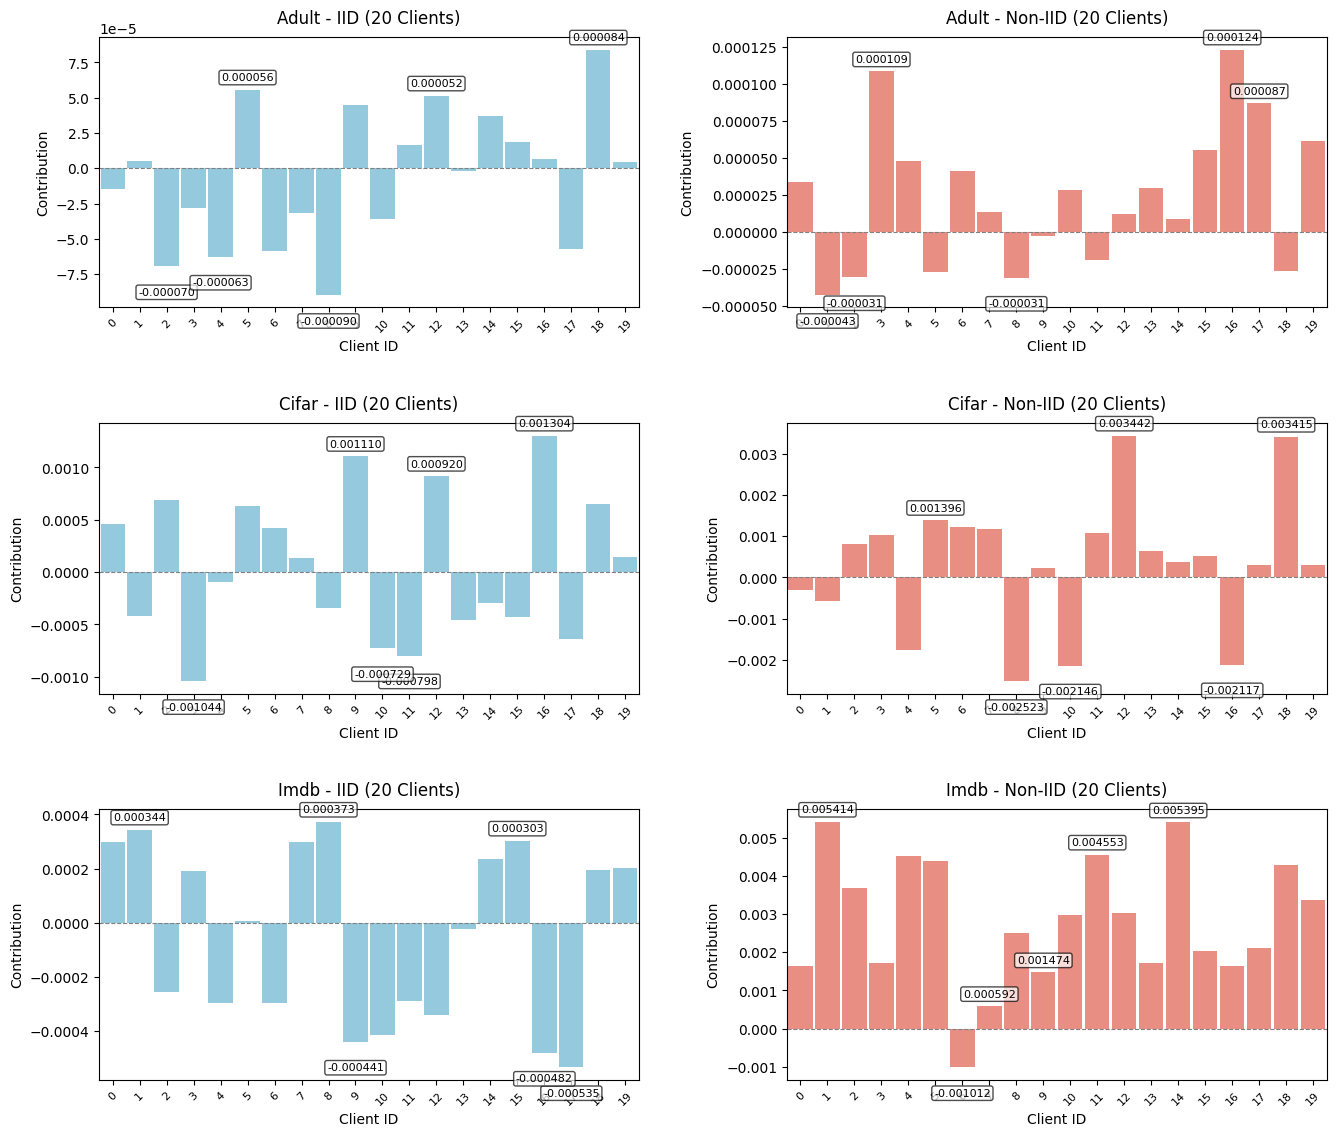

In [ ]:
# Prepare 20-client data and unstack
def prepare_data(dta):
    df_filtered = dta[dta['round'] != 1]
    return df_filtered.groupby(['dataset', 'partition', 'num_clients', 'client_id'])['contribution'].mean().unstack()

a_20 = prepare_data(adult_20)
an_20 = prepare_data(adultnoniid_20)
c_20 = prepare_data(cifar_20)
cn_20 = prepare_data(cifarnoniid_20)
i_20 = prepare_data(imdb_20)
in_20 = prepare_data(imdbnoniid_20)

# Create 3x2 subplot (3 datasets × 2 partitions)
fig, axes = plt.subplots(3, 2, figsize=(14, 12), sharex=False)

# Color palette
palette = {'IID': 'skyblue', 'Non-IID': 'salmon'}

# Data for plotting
plot_data = {
    ('adult', 'IID'): a_20,
    ('adult', 'Non-IID'): an_20,
    ('cifar', 'IID'): c_20,
    ('cifar', 'Non-IID'): cn_20,
    ('imdb', 'IID'): i_20,
    ('imdb', 'Non-IID'): in_20,
}

# Iterate through datasets and partitions to create plots
datasets = ['adult', 'cifar', 'imdb']
partitions = ['IID', 'Non-IID']

for i, dataset in enumerate(datasets):
    for j, partition in enumerate(partitions):
        ax = axes[i, j]
        data = plot_data[(dataset, partition)]
        df_melted = data.melt(var_name='client_id', value_name='contribution')
        sns.barplot(
            data=df_melted,
            x='client_id',
            y='contribution',
            color=palette[partition],
            ax=ax,
            width=0.9
        )
        ax.axhline(0, color='gray', linestyle='--', linewidth=0.8)
        ax.set_title(f"{dataset.capitalize()} - {partition} (20 Clients)", pad=10, fontsize=12)
        ax.set_ylabel("Contribution", fontsize=10)
        ax.set_xlabel("Client ID", fontsize=10)
        ax.tick_params(axis='x', rotation=45, labelsize=8)

        # Add value labels to top/bottom contributors
        bars = sorted(ax.patches, key=lambda p: p.get_height())
        for p in bars[:3] + bars[-3:]:  # Label extremes only
            ax.annotate(
                f"{p.get_height():.6f}",
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center',
                va='bottom' if p.get_height() >= 0 else 'top',
                xytext=(0, 5 if p.get_height() >= 0 else -15),
                textcoords='offset points',
                fontsize=8,
                bbox=dict(boxstyle='round,pad=0.2', fc='white', alpha=0.7)
            )

plt.tight_layout(pad=3.0)
plt.show()

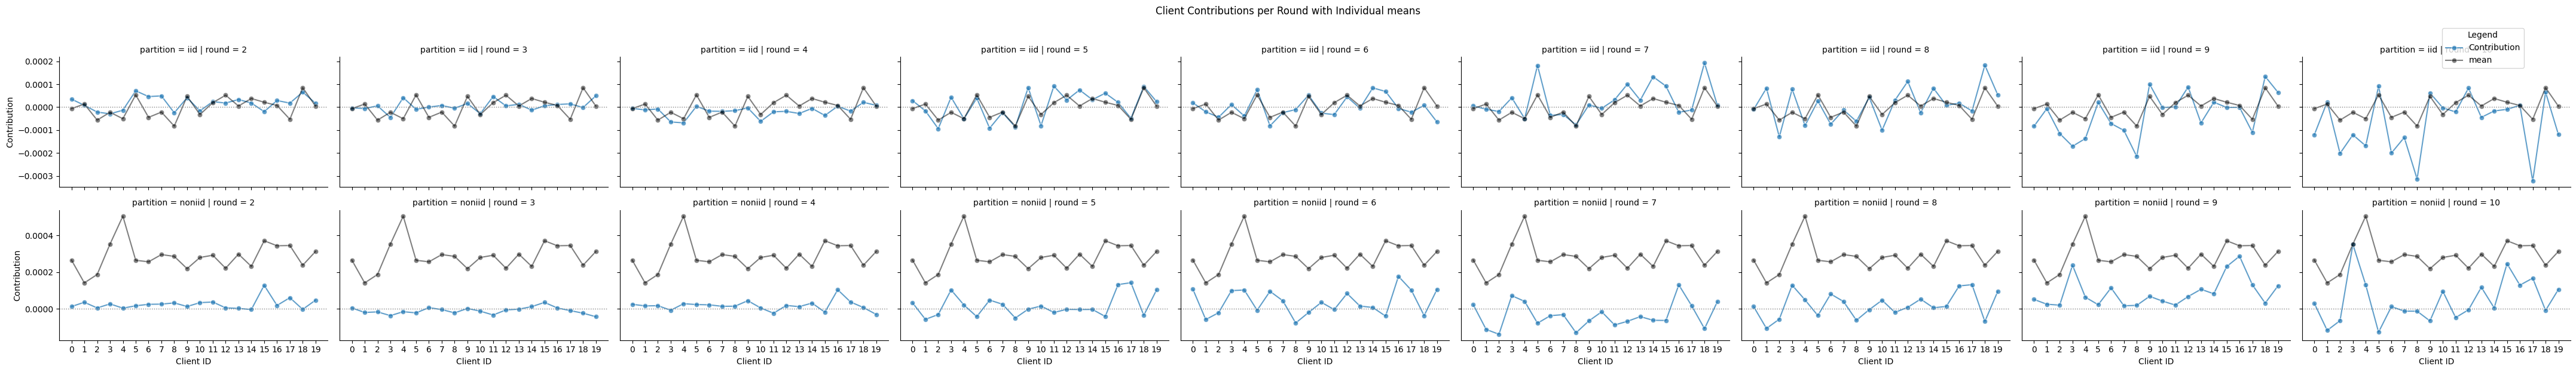

In [ ]:
data = adult_all_20.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()

mean_contrib = adult_all_20.groupby(['partition', 'client_id'])['contribution'].mean().reset_index()
mean_contrib.rename(columns={'contribution': 'mean_contribution'}, inplace=True)

data['client_id'] = data['client_id'].astype(str)
mean_contrib['client_id'] = mean_contrib['client_id'].astype(str)

data = data[data['round'] != 1]

def plot_contribution_with_mean(x, y, **kwargs): # Changed the function signature to accept x and y arguments
    # Get the current facet's data subset

    df = kwargs.pop('data')
    curr_partition = df['partition'].iloc[0]
    mean_subset = mean_contrib[mean_contrib['partition'] == curr_partition]

    df = df.merge(mean_subset, on=['client_id', 'partition'], how='left')

    # Plot actual contributions
    sns.lineplot(data=df, x=x, y=y, marker='o', alpha=0.7, label='Contribution') #Use x and y to specify columns
    # Plot mean
    sns.lineplot(data=df, x=x, y='mean_contribution', marker='o', color='black', alpha=0.5, label='mean')

    plt.axhline(y=0, color='gray', linestyle=':', linewidth=1)


g = sns.FacetGrid(
    data,
    row='partition',
    col='round',
    height=3,
    aspect=1.6,
    sharey='row',
)

g.map_dataframe(plot_contribution_with_mean, 'client_id', 'contribution') # Added 'client_id' and 'contribution' as arguments

# Axis labels and title
g.set_axis_labels("Client ID", "Contribution")
g.fig.suptitle("Client Contributions per Round with Individual means", y=1.03)

# Add a shared legend (from one subplot)
handles, labels = g.axes[0][0].get_legend_handles_labels()
g.fig.legend(handles=handles, labels=labels, title='Legend', loc='upper right', bbox_to_anchor=(0.98, 0.98))

plt.tight_layout()
plt.show()

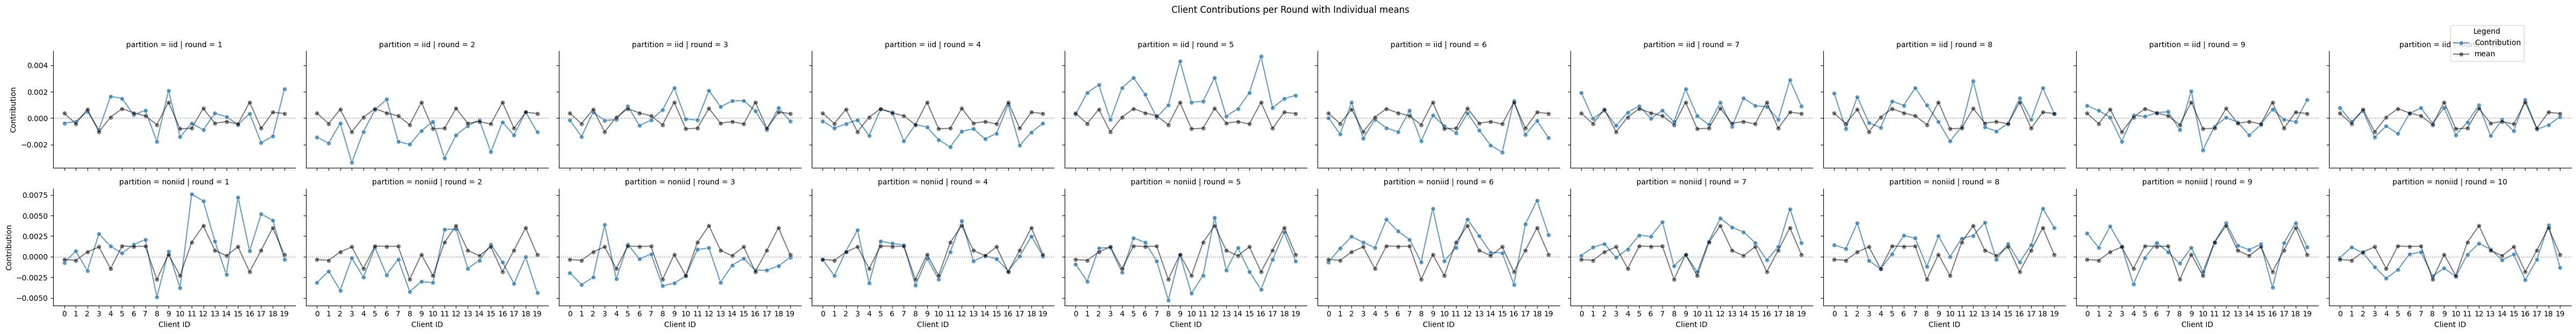

In [ ]:
data = cifar_all_20.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()

mean_contrib = cifar_all_20.groupby(['partition', 'client_id'])['contribution'].mean().reset_index()
mean_contrib.rename(columns={'contribution': 'mean_contribution'}, inplace=True)

data['client_id'] = data['client_id'].astype(str)
mean_contrib['client_id'] = mean_contrib['client_id'].astype(str)


def plot_contribution_with_mean(x, y, **kwargs): # Changed the function signature to accept x and y arguments
    # Get the current facet's data subset

    df = kwargs.pop('data')
    curr_partition = df['partition'].iloc[0]
    mean_subset = mean_contrib[mean_contrib['partition'] == curr_partition]

    df = df.merge(mean_subset, on=['client_id', 'partition'], how='left')

    # Plot actual contributions
    sns.lineplot(data=df, x=x, y=y, marker='o', alpha=0.7, label='Contribution') #Use x and y to specify columns
    # Plot mean
    sns.lineplot(data=df, x=x, y='mean_contribution', marker='o', color='black', alpha=0.5, label='mean')

    plt.axhline(y=0, color='gray', linestyle=':', linewidth=1)


g = sns.FacetGrid(
    data,
    row='partition',
    col='round',
    height=3,
    aspect=1.6,
    sharey='row',
)

g.map_dataframe(plot_contribution_with_mean, 'client_id', 'contribution') # Added 'client_id' and 'contribution' as arguments

# Axis labels and title
g.set_axis_labels("Client ID", "Contribution")
g.fig.suptitle("Client Contributions per Round with Individual means", y=1.03)

# Add a shared legend (from one subplot)
handles, labels = g.axes[0][0].get_legend_handles_labels()
g.fig.legend(handles=handles, labels=labels, title='Legend', loc='upper right', bbox_to_anchor=(0.98, 0.98))

plt.tight_layout()
plt.show()

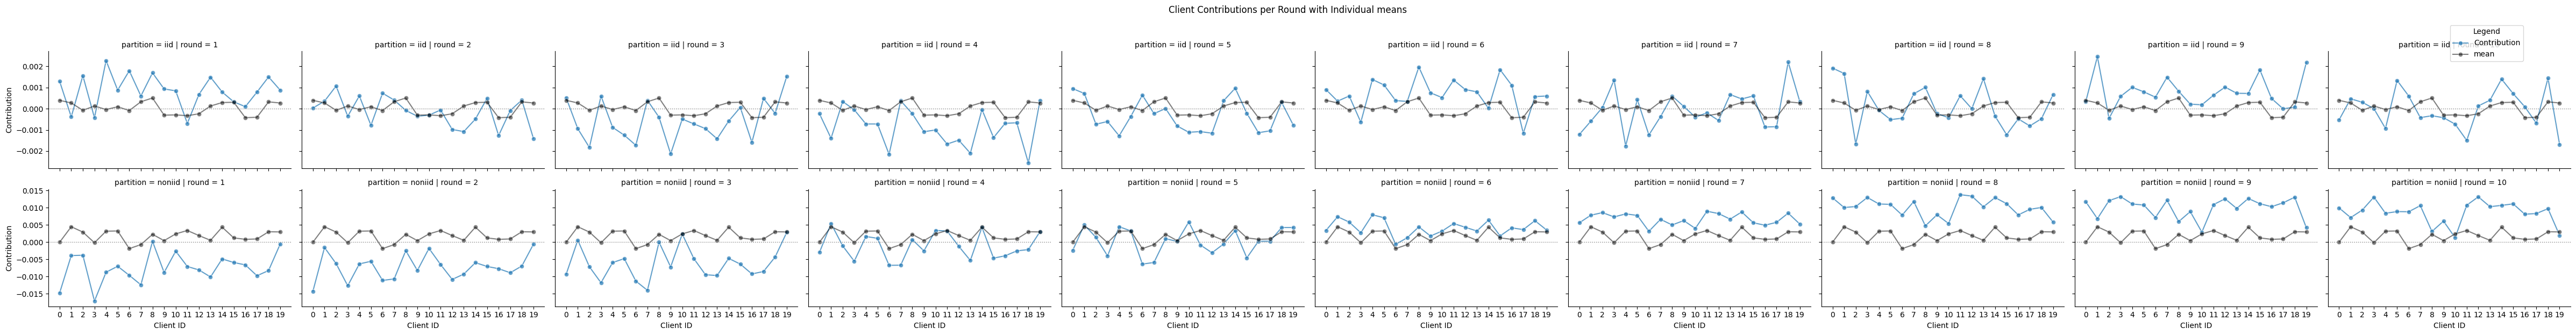

In [ ]:
data = imdb_all_20.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()

mean_contrib = imdb_all_20.groupby(['partition', 'client_id'])['contribution'].mean().reset_index()
mean_contrib.rename(columns={'contribution': 'mean_contribution'}, inplace=True)

data['client_id'] = data['client_id'].astype(str)
mean_contrib['client_id'] = mean_contrib['client_id'].astype(str)


def plot_contribution_with_mean(x, y, **kwargs): # Changed the function signature to accept x and y arguments
    # Get the current facet's data subset

    df = kwargs.pop('data')
    curr_partition = df['partition'].iloc[0]
    mean_subset = mean_contrib[mean_contrib['partition'] == curr_partition]

    df = df.merge(mean_subset, on=['client_id', 'partition'], how='left')

    # Plot actual contributions
    sns.lineplot(data=df, x=x, y=y, marker='o', alpha=0.7, label='Contribution') #Use x and y to specify columns
    # Plot mean
    sns.lineplot(data=df, x=x, y='mean_contribution', marker='o', color='black', alpha=0.5, label='mean')

    plt.axhline(y=0, color='gray', linestyle=':', linewidth=1)


g = sns.FacetGrid(
    data,
    row='partition',
    col='round',
    height=3,
    aspect=1.6,
    sharey='row',
)

g.map_dataframe(plot_contribution_with_mean, 'client_id', 'contribution') # Added 'client_id' and 'contribution' as arguments

# Axis labels and title
g.set_axis_labels("Client ID", "Contribution")
g.fig.suptitle("Client Contributions per Round with Individual means", y=1.03)

# Add a shared legend (from one subplot)
handles, labels = g.axes[0][0].get_legend_handles_labels()
g.fig.legend(handles=handles, labels=labels, title='Legend', loc='upper right', bbox_to_anchor=(0.98, 0.98))

plt.tight_layout()
plt.show()

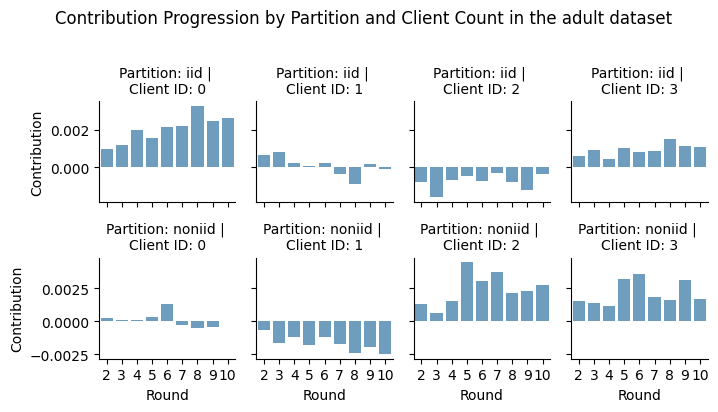

In [ ]:
data = adult_all_4.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()
data = data[data['round'] != 1]
# Create FacetGrid
g = sns.FacetGrid(
    data,
    row='partition',
    col='client_id',
    height=2,
    aspect=0.9,
    sharey='row'
)

g.map(sns.barplot, 'round', 'contribution', errorbar=None, alpha=0.7, order=range(2, 11))

# Set axis labels and title
g.set_titles(row_template='Partition: {row_name}', col_template='\nClient ID: {col_name}')
g.set_axis_labels("Round", "Contribution")
g.fig.suptitle("Contribution Progression by Partition and Client Count in the adult dataset", y=1.02)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/seaborn/axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


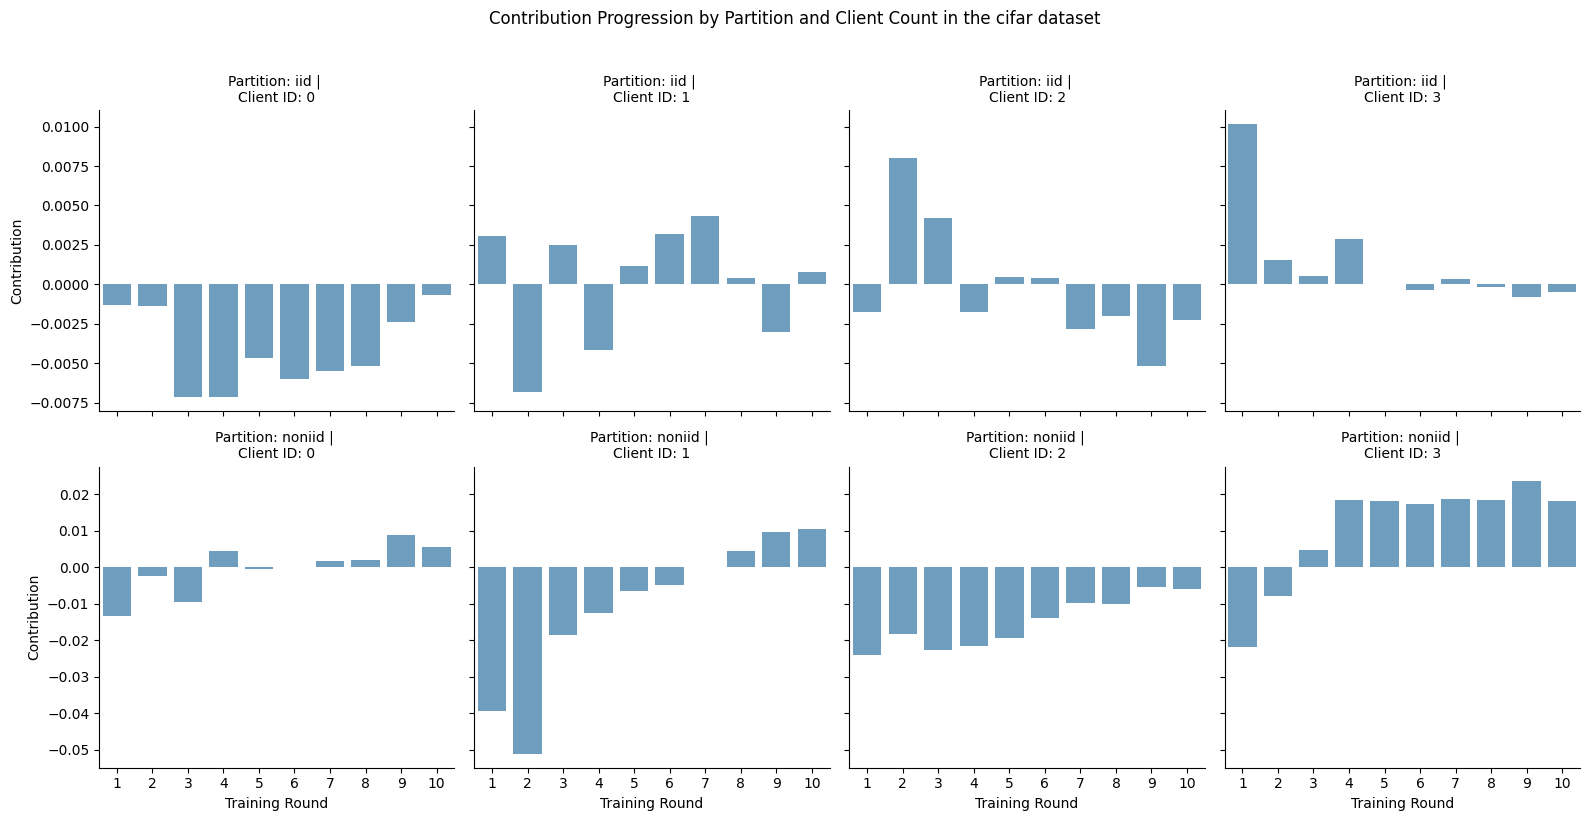

In [ ]:
data = cifar_all_4.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()

# Create FacetGrid
g = sns.FacetGrid(
    data,
    row='partition',
    col='client_id',
    height=4,
    sharey='row'
)

g.map(sns.barplot, 'round', 'contribution', errorbar=None, alpha=0.7)

# Set axis labels and title
g.set_titles(row_template='Partition: {row_name}', col_template='\nClient ID: {col_name}')
g.set_axis_labels("Training Round", "Contribution")
g.fig.suptitle("Contribution Progression by Partition and Client Count in the cifar dataset", y=1.02)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/seaborn/axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


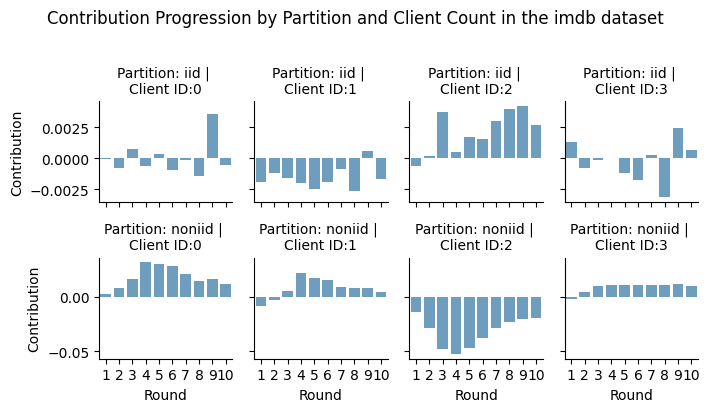

In [ ]:
data = imdb_all_4.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()

# Create FacetGrid
g = sns.FacetGrid(
    data,
    row='partition',
    col='client_id',
    height=2,
    aspect=0.9,
    sharey='row'
)

g.map(sns.barplot, 'round', 'contribution', errorbar=None, alpha=0.7)

# Set axis labels and title
g.set_titles(row_template='Partition: {row_name}', col_template='\nClient ID: {col_name}')
g.set_axis_labels("Round", "Contribution")
g.fig.suptitle("Contribution Progression by Partition and Client Count in the imdb dataset", y=1.02)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/seaborn/axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


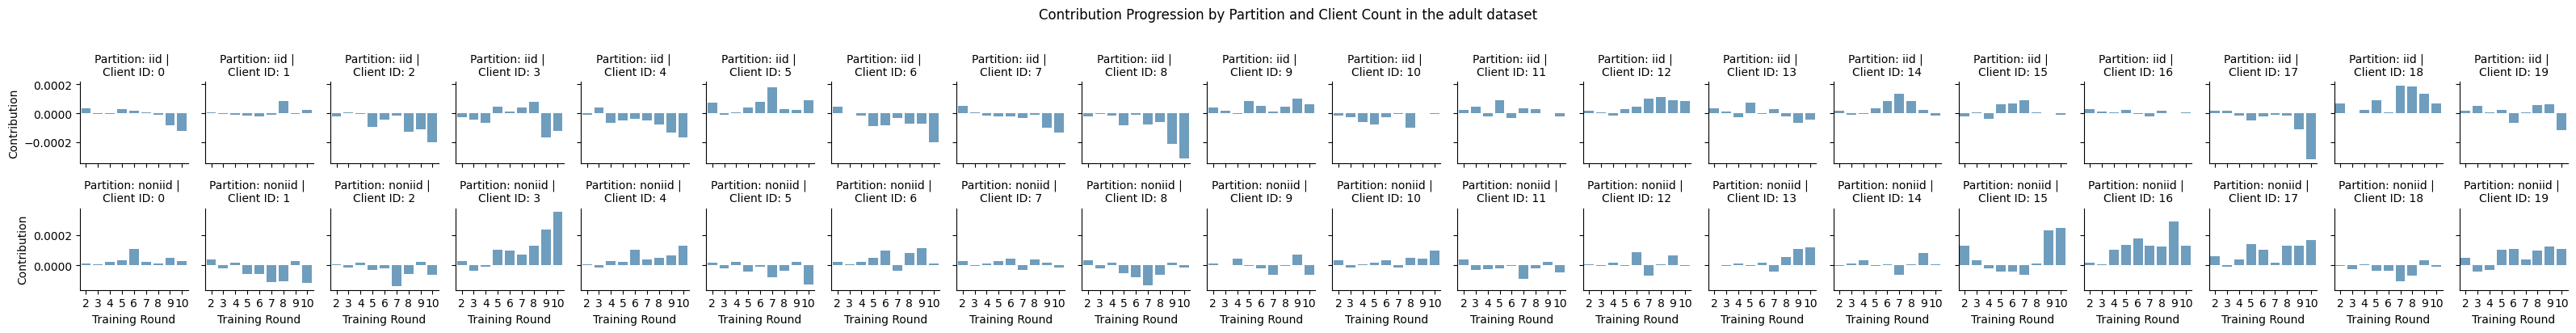

In [ ]:
data = adult_all_20.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()
data = data[(data['round'] >= 2) & (data['round'] <= 10)]

# Create FacetGrid
g = sns.FacetGrid(
    data,
    row='partition',
    col='client_id',
    height=2,
    aspect=0.8,
    sharey='row'
)

g.map(sns.barplot, 'round', 'contribution', errorbar=None, alpha=0.7)

# Set axis labels and title
g.set_titles(row_template='Partition: {row_name}', col_template='\nClient ID: {col_name}')
g.set_axis_labels("Training Round", "Contribution")
g.fig.suptitle("Contribution Progression by Partition and Client Count in the adult dataset", y=1.02)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/seaborn/axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


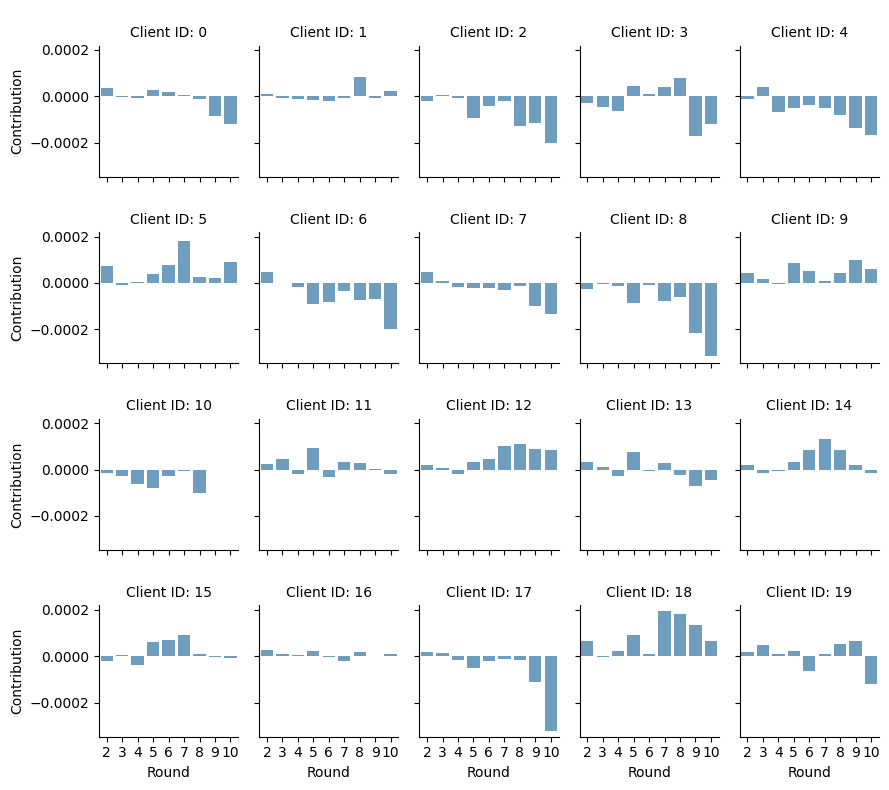

In [35]:
# Prepare data
data = adult_20.groupby(['client_id', 'round'])['contribution'].mean().reset_index()
data = data[(data['round'] >= 2) & (data['round'] <= 10)]

# Number of columns per row = total clients // 4 (adjust if needed)
g = sns.FacetGrid(
    data,
    col='client_id',
    col_wrap=5,  # adjust this to match 4 rows depending on number of clients
    height=2,
    aspect=0.9,
    sharey='row'
)

g.map(sns.barplot, 'round', 'contribution', errorbar=None, alpha=0.7)

# Set axis labels and title
g.set_titles(col_template='\nClient ID: {col_name}')
g.set_axis_labels("Round", "Contribution")

plt.tight_layout()
plt.show()


/usr/local/lib/python3.11/dist-packages/seaborn/axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


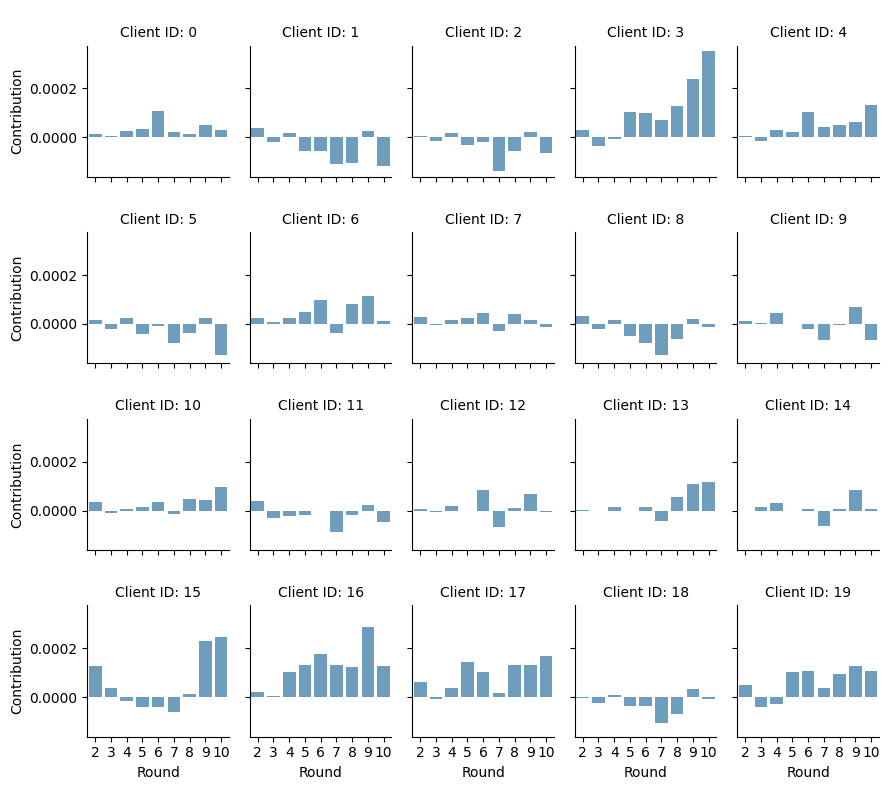

In [36]:
# Prepare data
data = adultnoniid_20.groupby(['client_id', 'round'])['contribution'].mean().reset_index()
data = data[(data['round'] >= 2) & (data['round'] <= 10)]

# Number of columns per row = total clients // 4 (adjust if needed)
g = sns.FacetGrid(
    data,
    col='client_id',
    col_wrap=5,  # adjust this to match 4 rows depending on number of clients
    height=2,
    aspect=0.9,
    sharey='row'
)

g.map(sns.barplot, 'round', 'contribution', errorbar=None, alpha=0.7)

# Set axis labels and title
g.set_titles(col_template='\nClient ID: {col_name}')
g.set_axis_labels("Round", "Contribution")

plt.tight_layout()
plt.show()


/usr/local/lib/python3.11/dist-packages/seaborn/axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


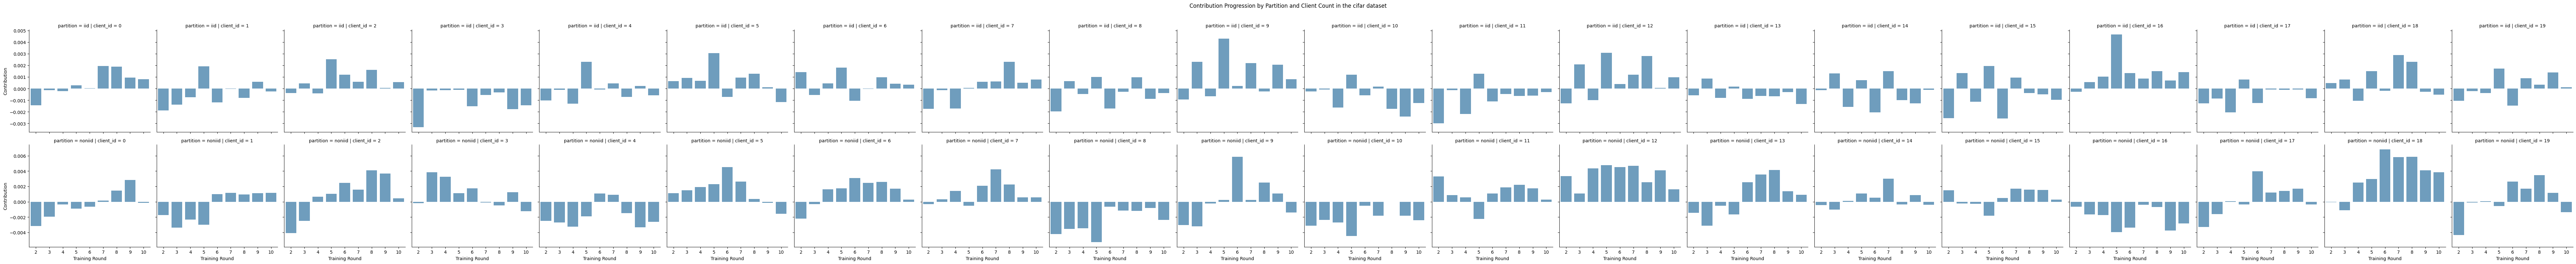

In [ ]:
data = cifar_all_20.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()
data = data[data['round'] != 1]

# Create FacetGrid
g = sns.FacetGrid(
    data,
    row='partition',
    col='client_id',
    height=4,
    sharey='row'
)

g.map(sns.barplot, 'round', 'contribution', errorbar=None, alpha=0.7)

# Set axis labels and title
g.set_titles(row_template='Partition: {row_name}', col_template='\nClient ID: {col_name}')
g.set_axis_labels("Training Round", "Contribution")
g.fig.suptitle("Contribution Progression by Partition and Client Count in the cifar dataset", y=1.02)

plt.tight_layout()
plt.show()

/usr/local/lib/python3.11/dist-packages/seaborn/axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


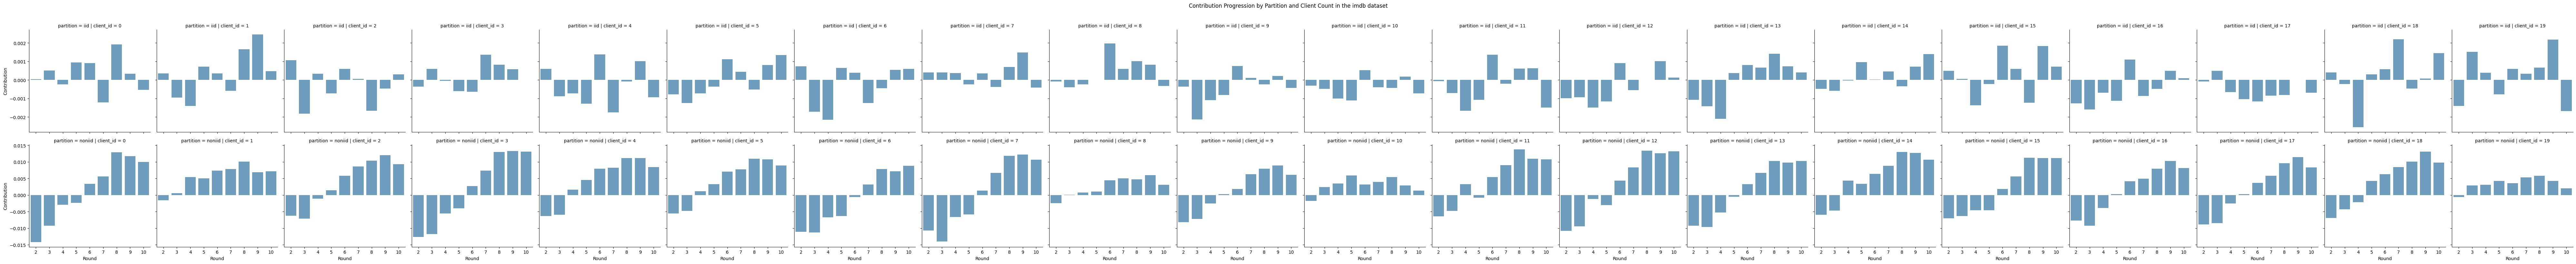

In [ ]:
data = imdb_all_20.groupby(['partition', 'client_id', 'round'])['contribution'].mean().reset_index()
data = data[data['round'] != 1]

# Create FacetGrid
g = sns.FacetGrid(
    data,
    row='partition',
    col='client_id',
    height=4,
    sharey='row'
)

g.map(sns.barplot, 'round', 'contribution', errorbar=None, alpha=0.7)

# Set axis labels and title
g.set_titles(row_template='Partition: {row_name}', col_template='\nClient ID: {col_name}')
g.set_axis_labels("Round", "Contribution")
g.fig.suptitle("Contribution Progression by Partition and Client Count in the imdb dataset", y=1.02)

plt.tight_layout()
plt.show()

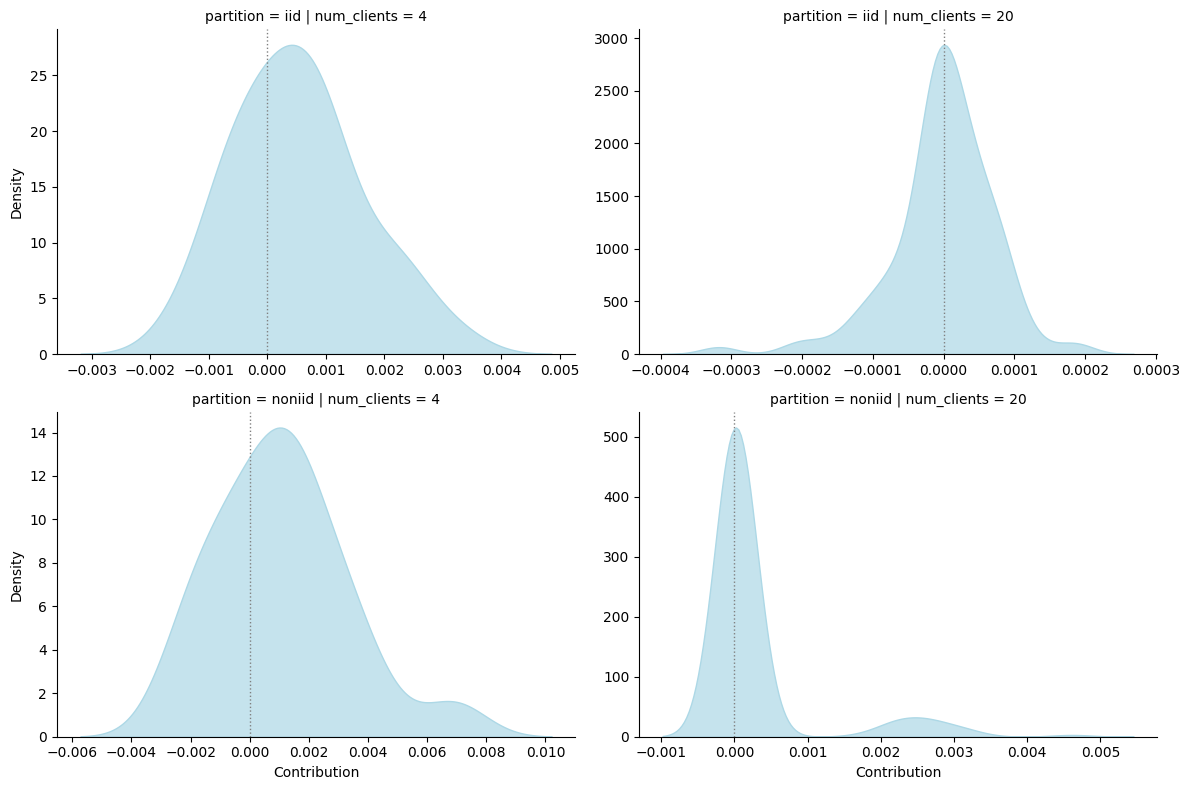

In [37]:
data_a = adult_all.groupby(['partition', 'client_id', 'num_clients','round'])['contribution'].mean().reset_index()
data = data[data['round'] != 1]

# Create KDE plots faceted by number of clients
g = sns.displot(
    data=data_a,
    x='contribution',
    kind='kde',
    col='num_clients',
    row='partition',
    fill=True,
    alpha=0.7,
    color='lightblue',
    height=4,
    aspect=1.5,
    facet_kws={'sharex': False, 'sharey': False}
)

# Set global title and axis labels
#g.fig.suptitle("Distribution of Contributions - adult", y=1.03)
g.set_axis_labels("Contribution", "Density")

for ax in g.axes.flat:
    ax.axvline(x=0.0, color='gray', linestyle=':', linewidth=1)

plt.show()



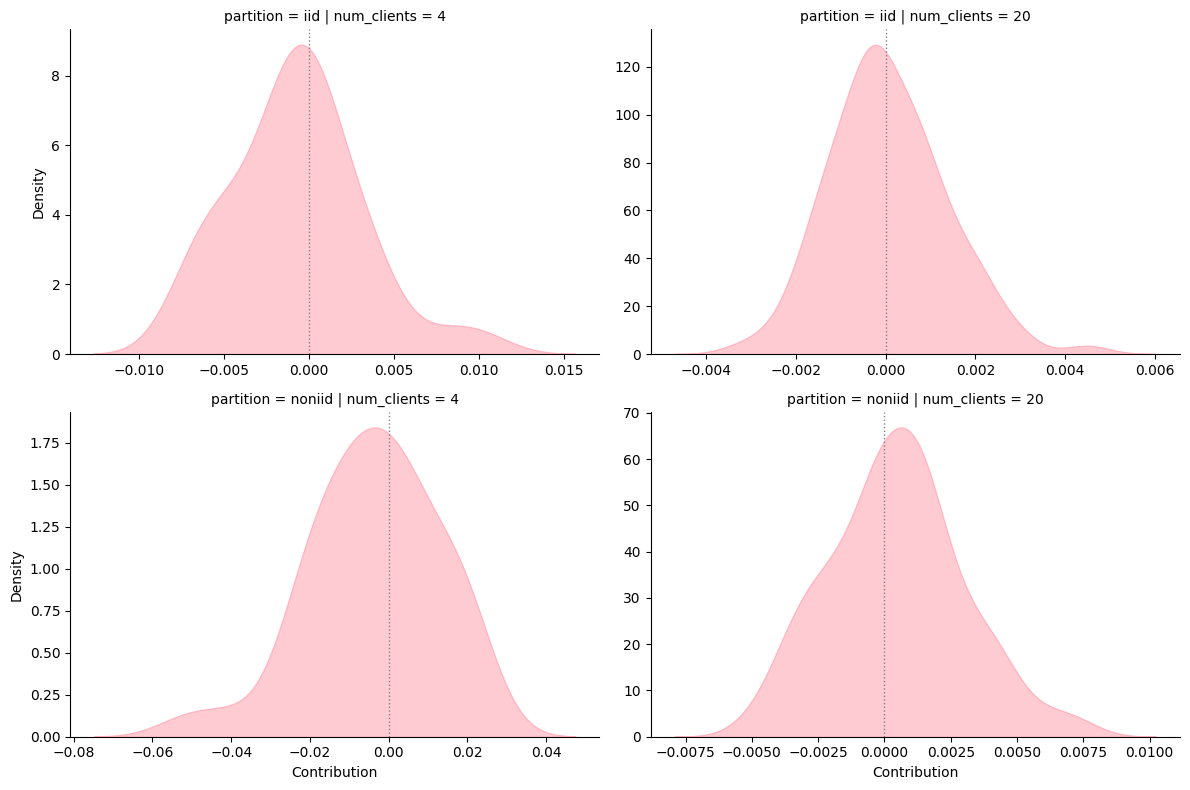

In [5]:
data_c = cifar_all.groupby(['partition', 'client_id', 'num_clients','round'])['contribution'].mean().reset_index()

# Create KDE plots faceted by number of clients
g = sns.displot(
    data=data_c,
    x='contribution',
    kind='kde',
    col='num_clients',
    row='partition',
    fill=True,
    alpha=0.7,
    color='lightpink',
    height=4,
    aspect=1.5,
    facet_kws={'sharex': False, 'sharey': False}
)

# Set global title and axis labels
#g.fig.suptitle("Distribution of Contributions - cifar", y=1.03)
g.set_axis_labels("Contribution", "Density")

for ax in g.axes.flat:
    ax.axvline(x=0.0, color='gray', linestyle=':', linewidth=1)

plt.show()



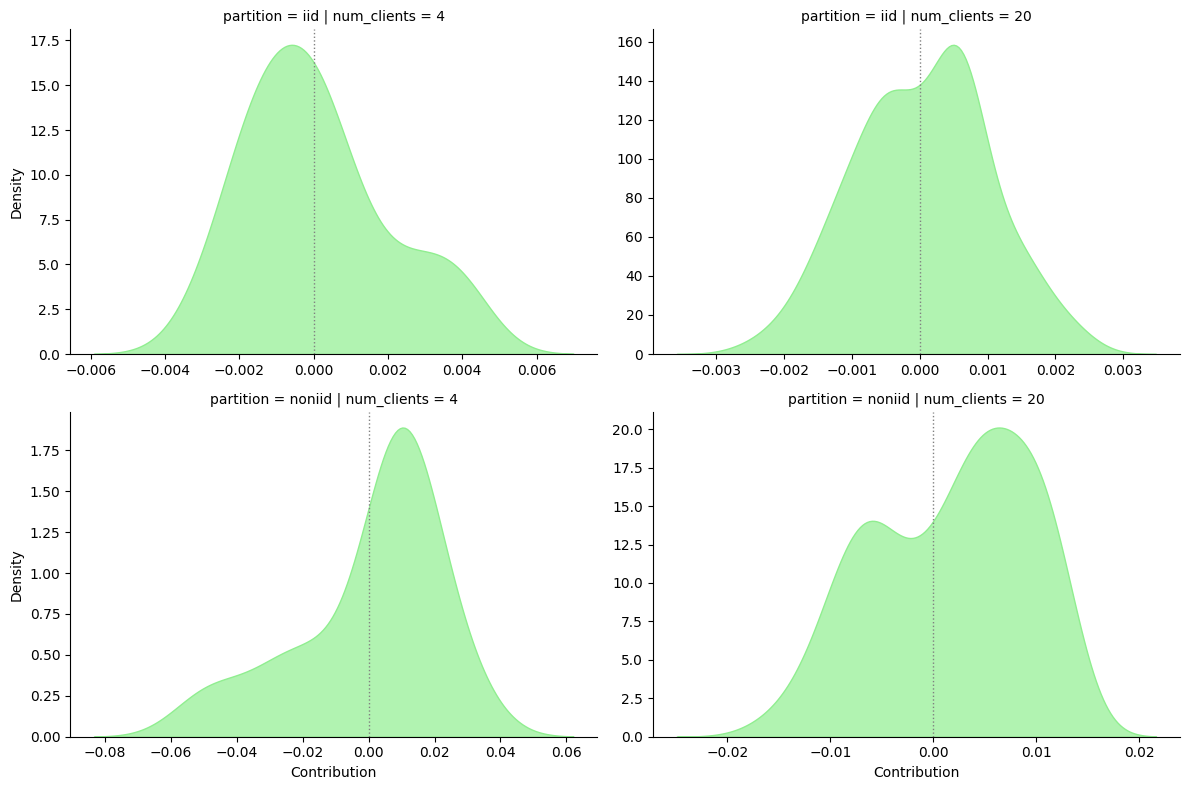

In [8]:
data_i = imdb_all.groupby(['partition', 'client_id', 'num_clients','round'])['contribution'].mean().reset_index()

# Create KDE plots faceted by number of clients
g = sns.displot(
    data=data_i,
    x='contribution',
    kind='kde',
    col='num_clients',
    row='partition',
    fill=True,
    alpha=0.7,
    color='lightgreen',
    height=4,
    aspect=1.5,
    facet_kws={'sharex': False, 'sharey': False}
)

# Set global title and axis labels
#g.fig.suptitle("Distribution of Contributions - imdb", y=1.03)
g.set_axis_labels("Contribution", "Density")

for ax in g.axes.flat:
    ax.axvline(x=0.0, color='gray', linestyle=':', linewidth=1)

plt.show()

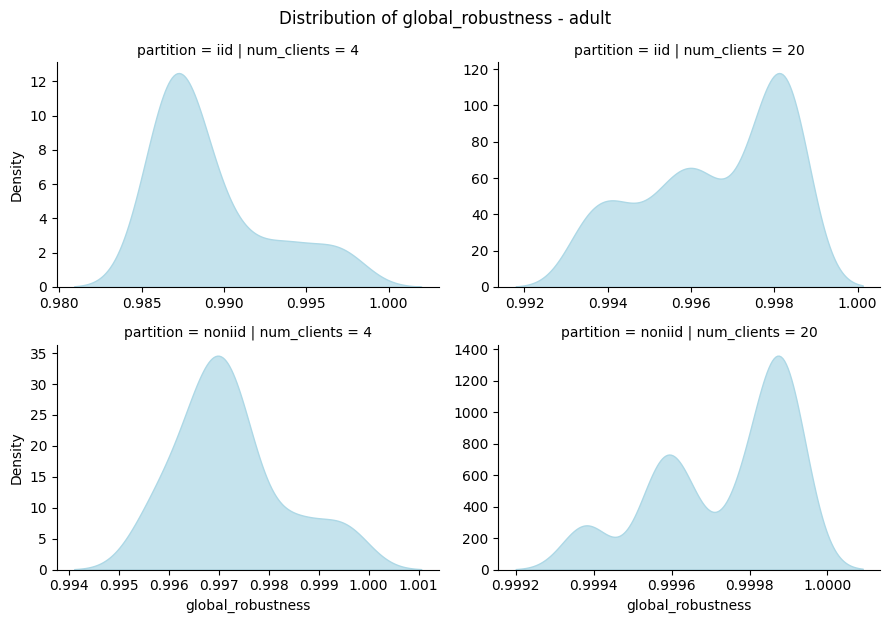

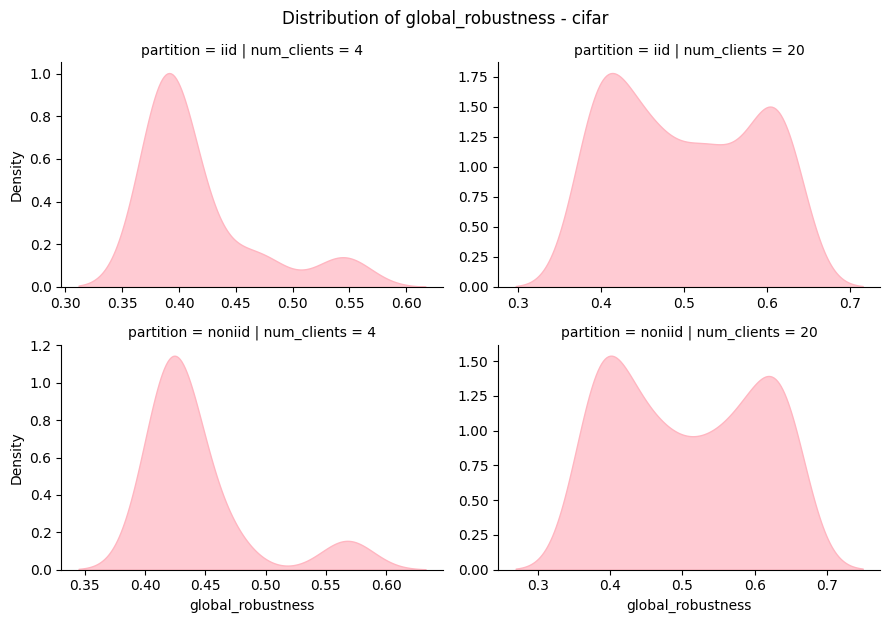

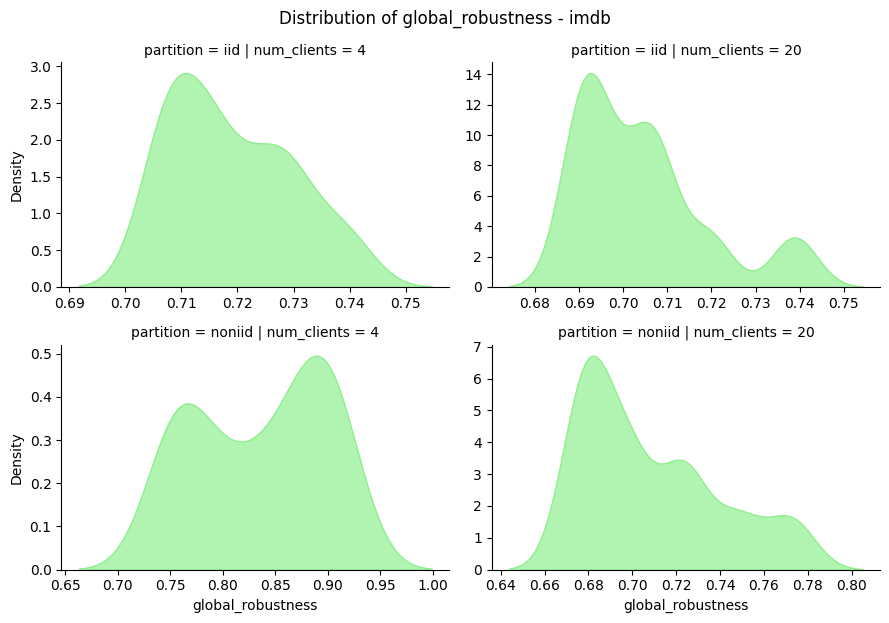

In [ ]:
data_a = adult_all.groupby(['partition', 'client_id', 'num_clients', 'round'])['global_robustness'].mean().reset_index()
data_c = cifar_all.groupby(['partition', 'client_id', 'num_clients', 'round'])['global_robustness'].mean().reset_index()
data_i = imdb_all.groupby(['partition', 'client_id', 'num_clients', 'round'])['global_robustness'].mean().reset_index()

# Create KDE plots faceted by number of clients
g = sns.displot(
    data=data_a,
    x='global_robustness',
    kind='kde',
    col='num_clients',
    row='partition',
    fill=True,
    color='lightblue',
    alpha=0.7,
    height=3,
    aspect=1.5,
    facet_kws={'sharex': False, 'sharey': False}
)

# Set global title and axis labels
g.fig.suptitle("Distribution of global_robustness - adult", y=1.03)
g.set_axis_labels("global_robustness", "Density")

plt.show()

# Create KDE plots faceted by number of clients
g = sns.displot(
    data=data_c,
    x='global_robustness',
    kind='kde',
    col='num_clients',
    row='partition',
    fill=True,
    color='lightpink',
    alpha=0.7,
    height=3,
    aspect=1.5,
    facet_kws={'sharex': False, 'sharey': False}
)

# Set global title and axis labels
g.fig.suptitle("Distribution of global_robustness - cifar", y=1.03)
g.set_axis_labels("global_robustness", "Density")

plt.show()

# Create KDE plots faceted by number of clients
g = sns.displot(
    data=data_i,
    x='global_robustness',
    kind='kde',
    col='num_clients',
    row='partition',
    fill=True,
    alpha=0.7,
    color='lightgreen',
    height=3,
    aspect=1.5,
    facet_kws={'sharex': False, 'sharey': False}
)

# Set global title and axis labels
g.fig.suptitle("Distribution of global_robustness - imdb", y=1.03)
g.set_axis_labels("global_robustness", "Density")

plt.show()

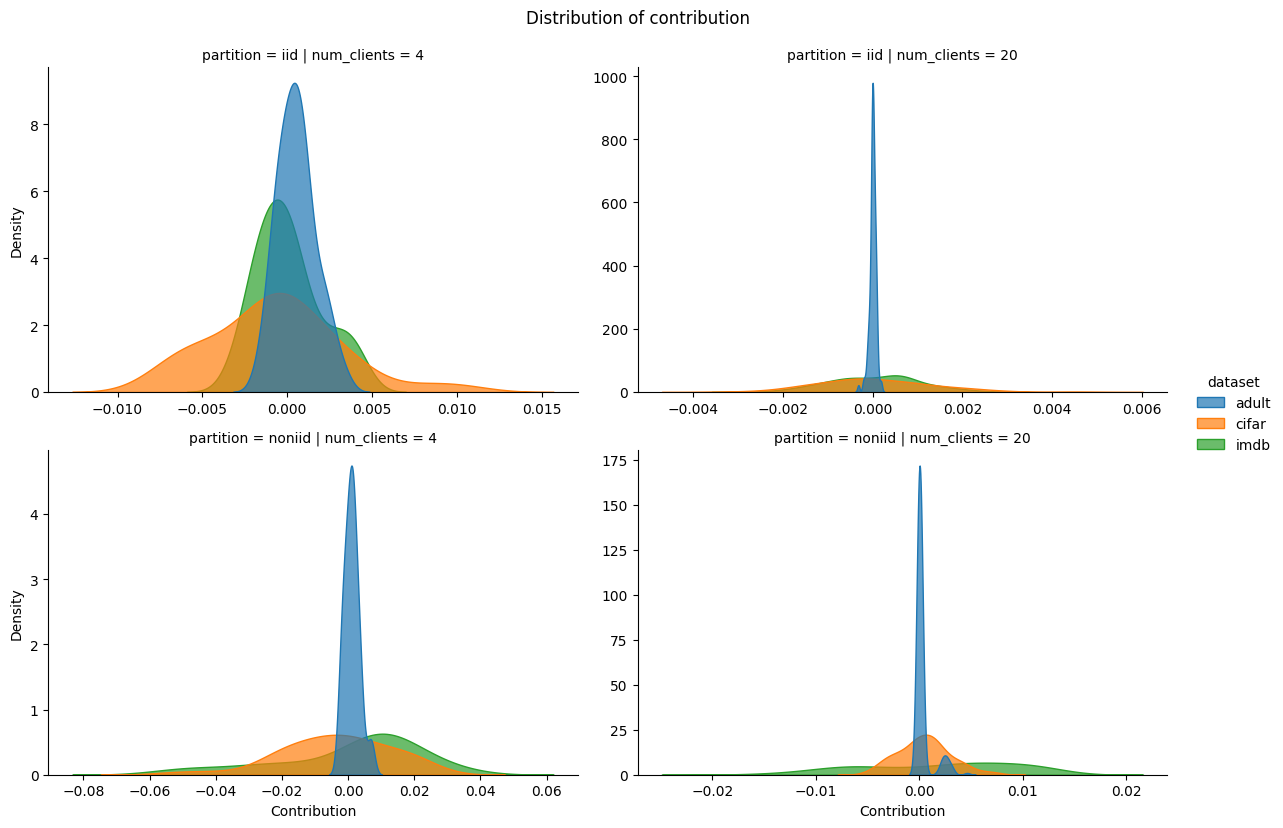

In [ ]:
data = df.groupby(['dataset','partition', 'client_id', 'num_clients', 'round'])['contribution'].mean().reset_index()

# Create KDE plots faceted by number of clients
g = sns.displot(
    data=data,
    x='contribution',
    kind='kde',
    col='num_clients',
    row='partition',
    hue='dataset',
    fill=True,
    alpha=0.7,
    height=4,
    aspect=1.5,
    facet_kws={'sharex': False, 'sharey': False}
)

# Set global title and axis labels
g.fig.suptitle("Distribution of contribution", y=1.03)
g.set_axis_labels("Contribution", "Density")

plt.show()

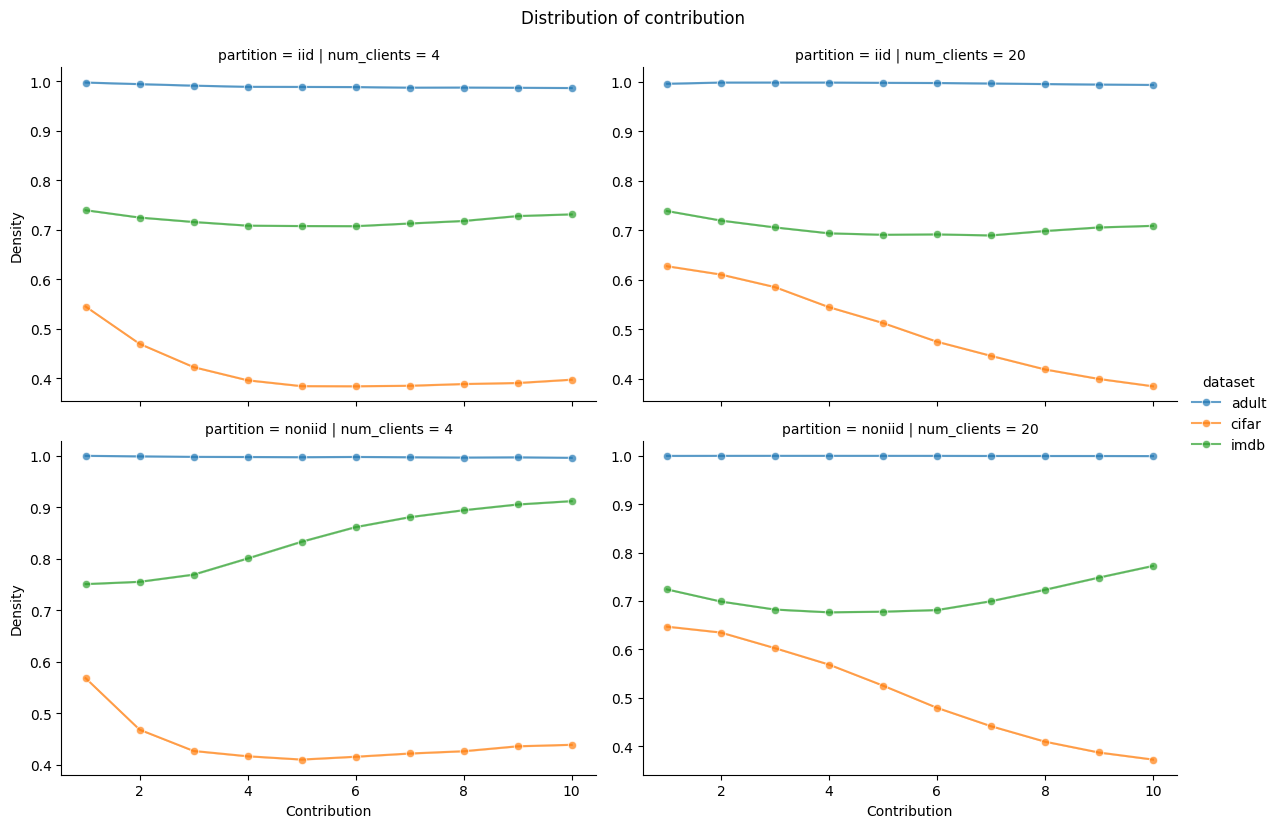

In [ ]:
data = df.groupby(['dataset','partition', 'client_id', 'num_clients', 'round'])['global_robustness'].mean().reset_index()

g = sns.FacetGrid(
    data=data,
    col='num_clients',
    row='partition',
    hue='dataset',
    height=4,
    aspect=1.5,
    sharey=False
)

g.map(sns.lineplot, 'round', 'global_robustness', marker='o', alpha=0.7)
g.add_legend()
# Set global title and axis labels
g.fig.suptitle("Distribution of contribution", y=1.03)
g.set_axis_labels("Contribution", "Density")

plt.show()

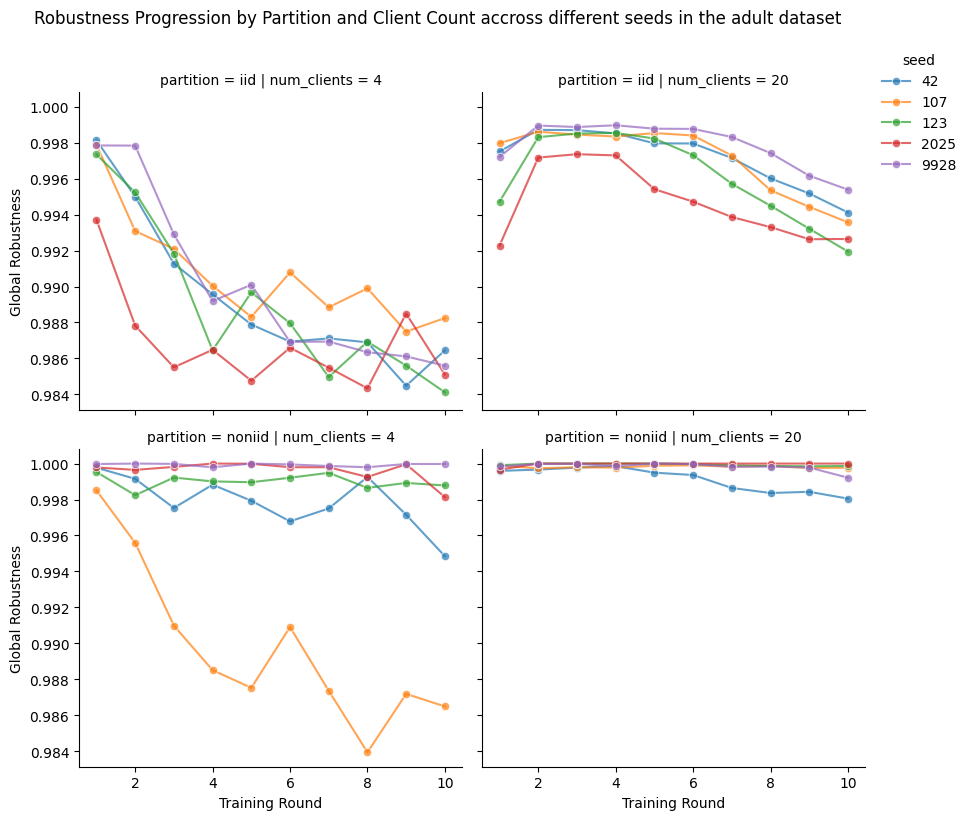

In [ ]:
data = adult_all.groupby(['dataset', 'seed', 'partition', 'num_clients', 'round'])['global_robustness'].mean().reset_index()
g = sns.FacetGrid(
    data,
    row='partition',
    col='num_clients',
    hue='seed',
    height=4,
    sharey=True
)
g.map(sns.lineplot, 'round', 'global_robustness', marker='o', alpha=0.7)
g.add_legend(loc='upper right', bbox_to_anchor=(1.1, 0.98))
g.set_axis_labels("Training Round", "Global Robustness")
g.fig.suptitle("Robustness Progression by Partition and Client Count accross different seeds in the adult dataset", y=1.02)
plt.tight_layout()
plt.show()

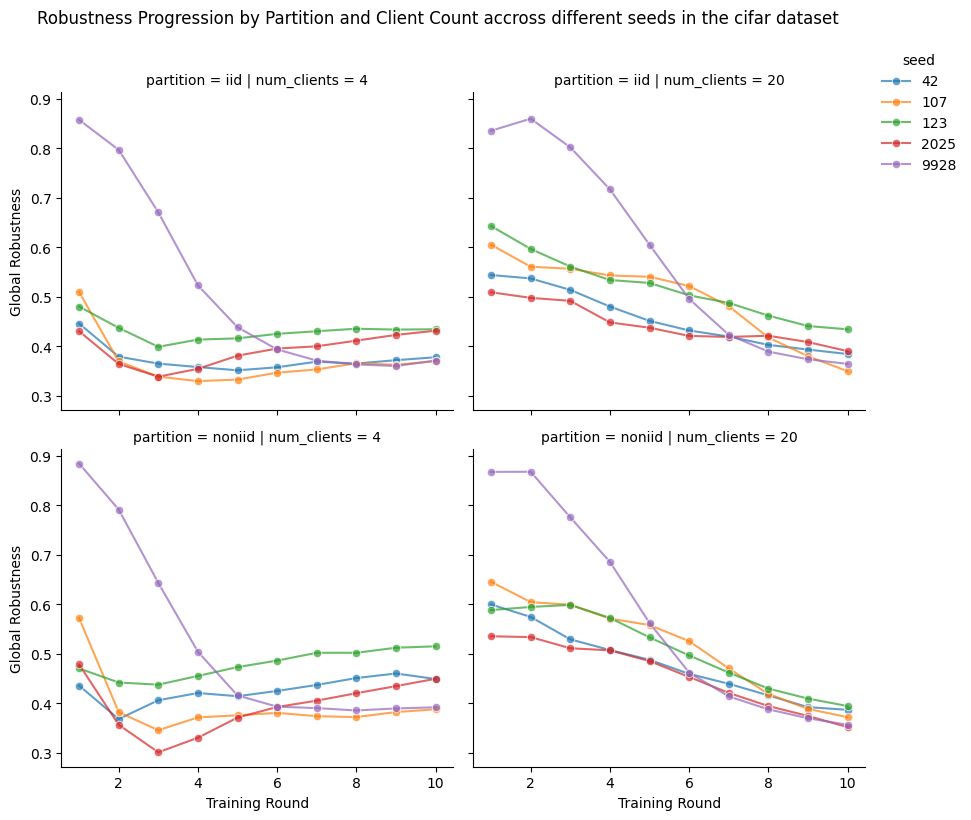

In [ ]:
data = cifar_all.groupby(['dataset', 'seed', 'partition', 'num_clients', 'round'])['global_robustness'].mean().reset_index()
g = sns.FacetGrid(
    data,
    row='partition',
    col='num_clients',
    hue='seed',
    height=4,
    sharey=True
)
g.map(sns.lineplot, 'round', 'global_robustness', marker='o', alpha=0.7)
g.add_legend(loc='upper right', bbox_to_anchor=(1.1, 0.98))
g.set_axis_labels("Training Round", "Global Robustness")
g.fig.suptitle("Robustness Progression by Partition and Client Count accross different seeds in the cifar dataset", y=1.02)
plt.tight_layout()
plt.show()

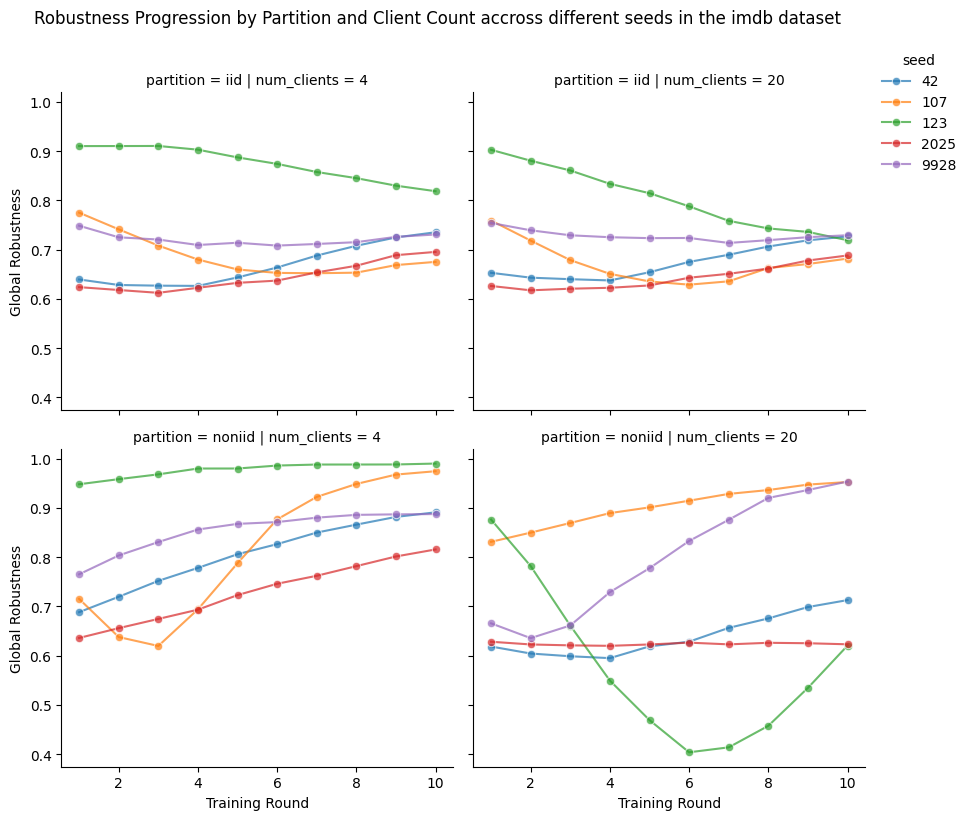

In [ ]:
data = imdb_all.groupby(['dataset', 'seed', 'partition', 'num_clients', 'round'])['global_robustness'].mean().reset_index()
g = sns.FacetGrid(
    data,
    row='partition',
    col='num_clients',
    hue='seed',
    height=4,
    sharey=True
)
g.map(sns.lineplot, 'round', 'global_robustness', marker='o', alpha=0.7)
g.add_legend(loc='upper right', bbox_to_anchor=(1.1, 0.98))
g.set_axis_labels("Training Round", "Global Robustness")
g.fig.suptitle("Robustness Progression by Partition and Client Count accross different seeds in the imdb dataset", y=1.02)
plt.tight_layout()
plt.show()

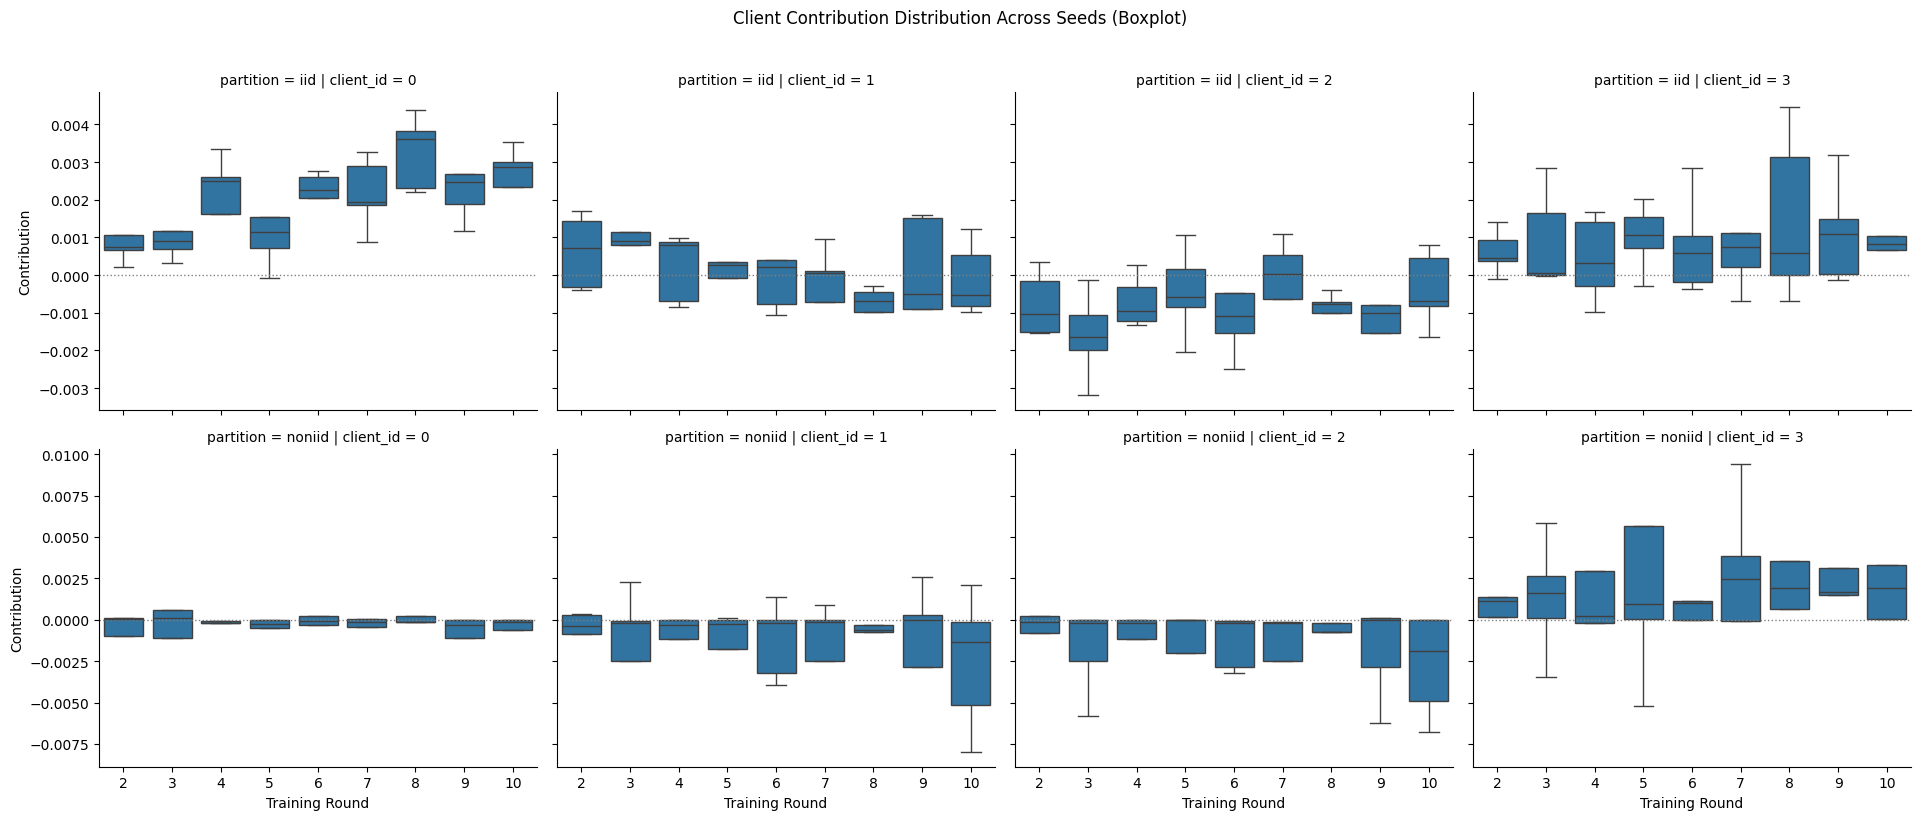

In [ ]:
# Group and filter data
data = adult_all_4.groupby(['partition', 'client_id', 'round', 'seed'])['contribution'].mean().reset_index()

data = data[(data['round'] >= 2) & (data['round'] <= 10)]

# Create the FacetGrid with boxplots
g = sns.catplot(
    data=data,
    x='round',
    y='contribution',
    col='client_id',
    row='partition',
    kind='box',
    height=4,
    aspect=1.2,
    sharey='row',
    showfliers=False,  # Hide outliers if too noisy
)

# Set axis labels and title
g.set_axis_labels("Training Round", "Contribution")
g.fig.suptitle("Client Contribution Distribution Across Seeds (Boxplot)", y=1.02)
for ax in g.axes.flat:
    ax.axhline(y=0.0, color='gray', linestyle=':', linewidth=1)


plt.tight_layout()
plt.show()


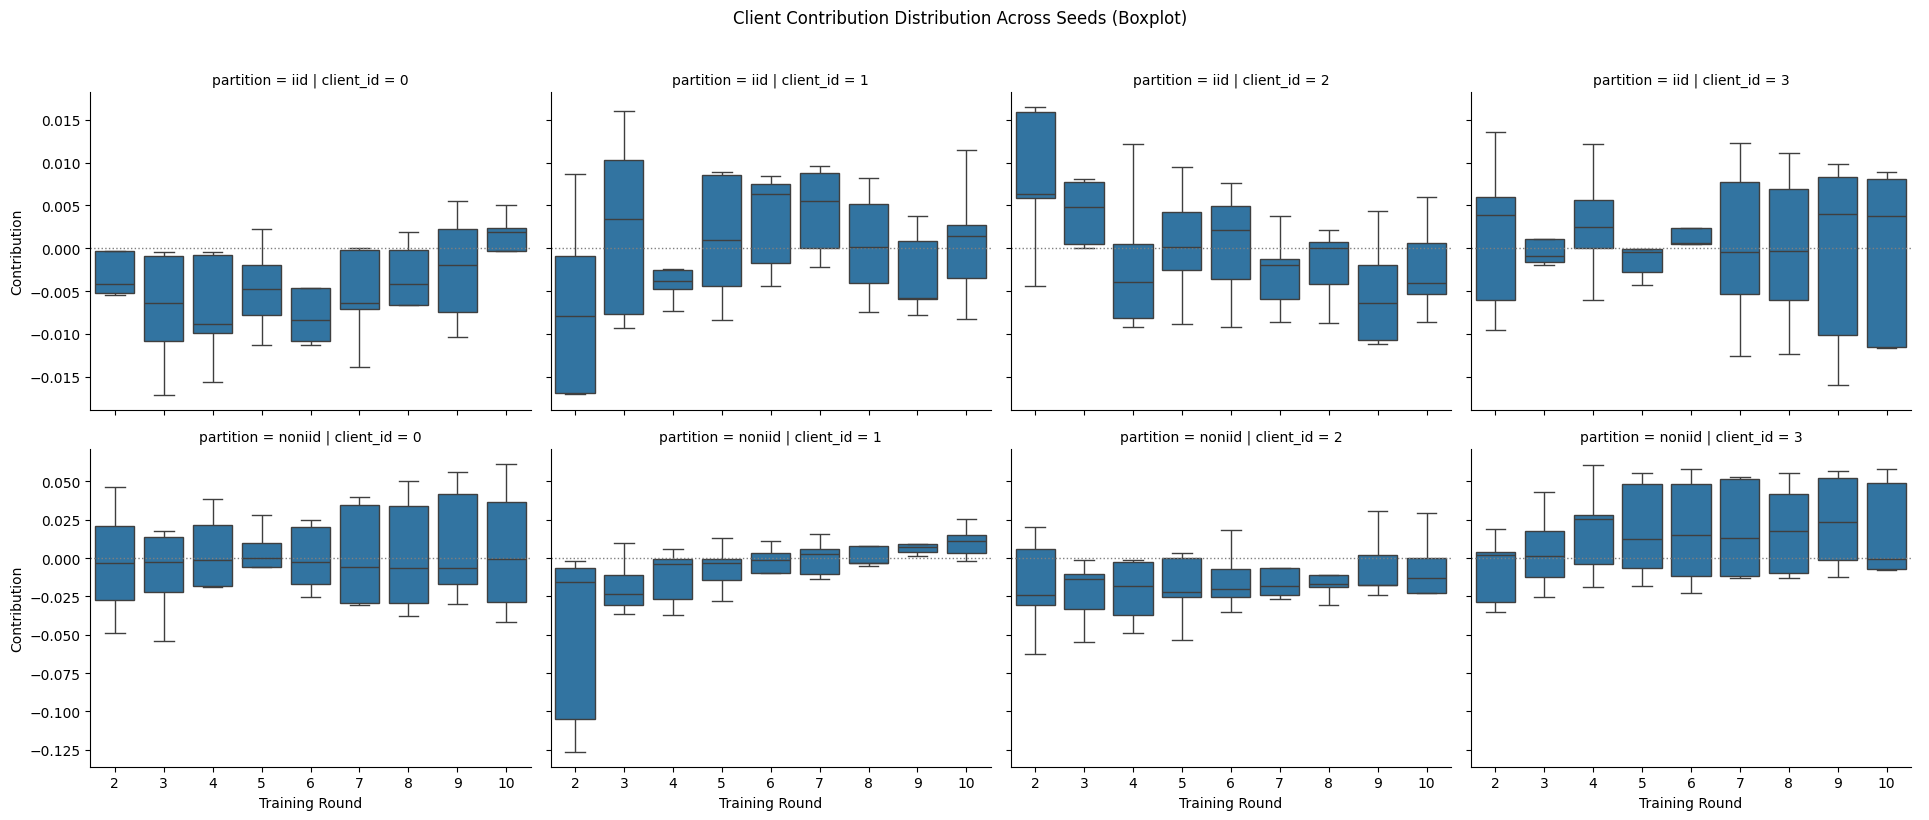

In [ ]:
# Group and filter data
data = cifar_all_4.groupby(['partition', 'client_id', 'round', 'seed'])['contribution'].mean().reset_index()

data = data[(data['round'] >= 2) & (data['round'] <= 10)]

# Create the FacetGrid with boxplots
g = sns.catplot(
    data=data,
    x='round',
    y='contribution',
    col='client_id',
    row='partition',
    kind='box',
    height=4,
    aspect=1.2,
    sharey='row',
    showfliers=False,  # Hide outliers if too noisy
)

# Set axis labels and title
g.set_axis_labels("Training Round", "Contribution")
g.fig.suptitle("Client Contribution Distribution Across Seeds (Boxplot)", y=1.02)
for ax in g.axes.flat:
    ax.axhline(y=0.0, color='gray', linestyle=':', linewidth=1)


plt.tight_layout()
plt.show()


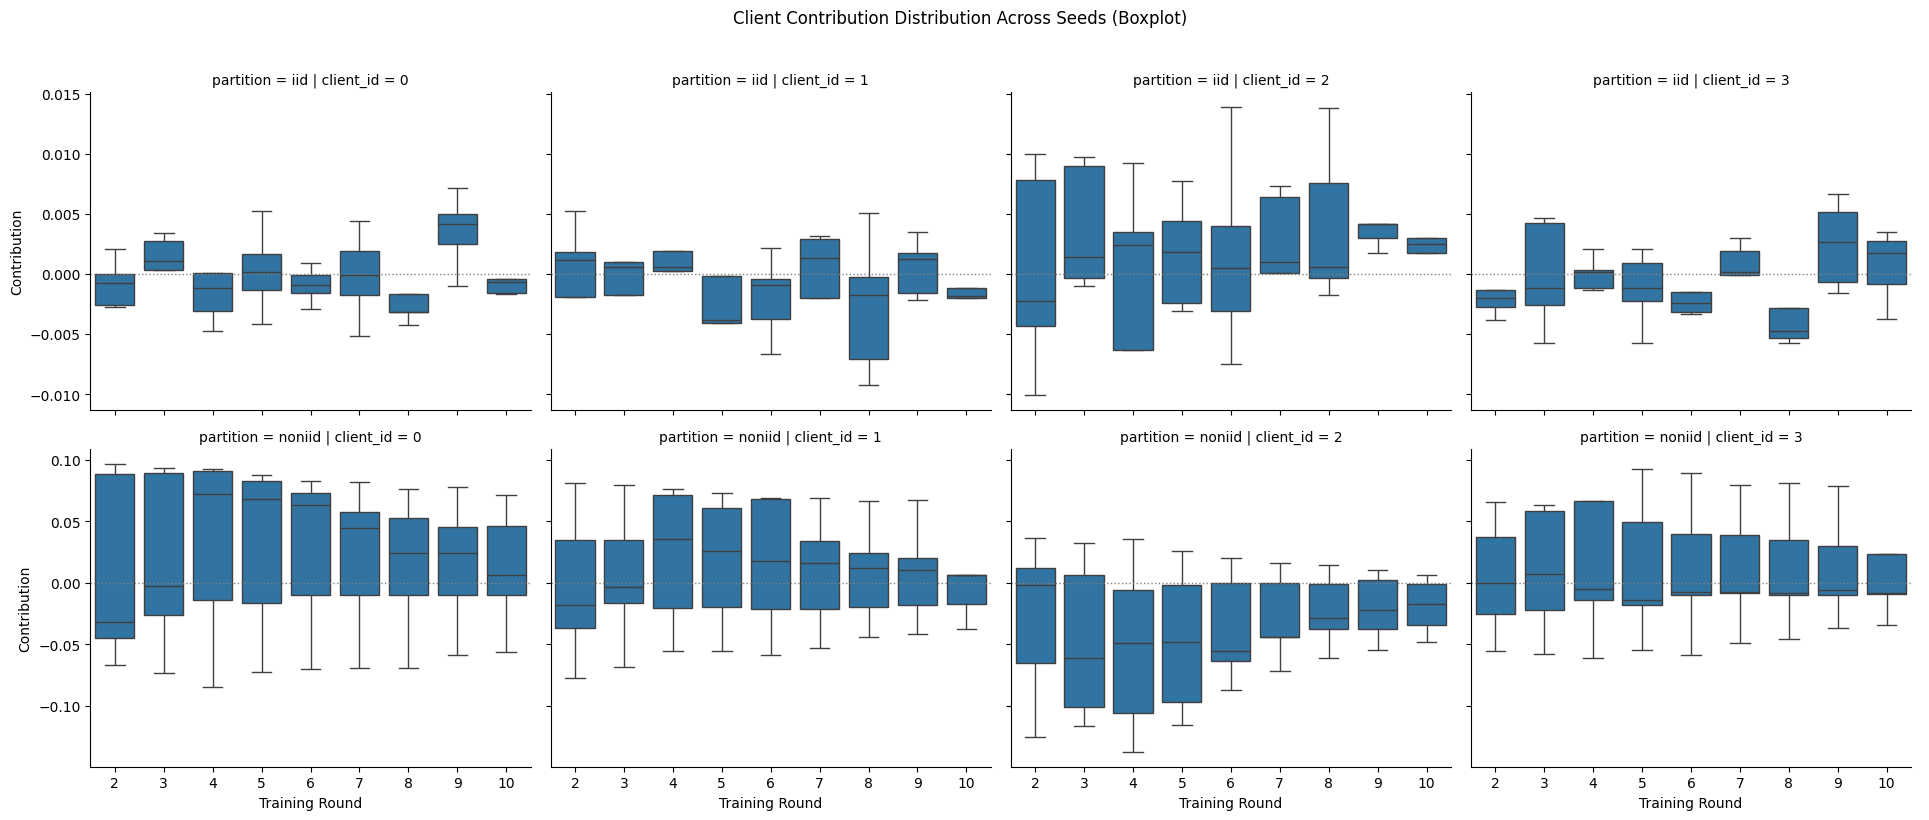

In [ ]:
# Group and filter data
data = imdb_all_4.groupby(['partition', 'client_id', 'round', 'seed'])['contribution'].mean().reset_index()

data = data[(data['round'] >= 2) & (data['round'] <= 10)]

# Create the FacetGrid with boxplots
g = sns.catplot(
    data=data,
    x='round',
    y='contribution',
    col='client_id',
    row='partition',
    kind='box',
    height=4,
    aspect=1.2,
    sharey='row',
    showfliers=False,  # Hide outliers if too noisy
)

# Set axis labels and title
g.set_axis_labels("Training Round", "Contribution")
g.fig.suptitle("Client Contribution Distribution Across Seeds (Boxplot)", y=1.02)
for ax in g.axes.flat:
    ax.axhline(y=0.0, color='gray', linestyle=':', linewidth=1)


plt.tight_layout()
plt.show()


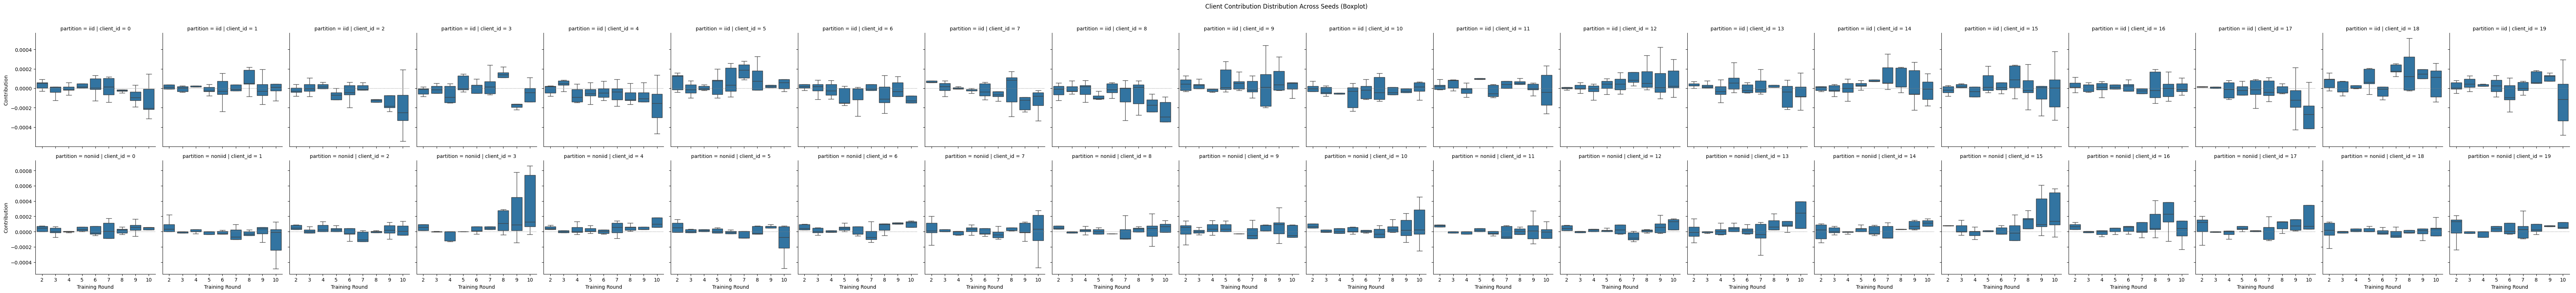

In [ ]:
# Group and filter data
data = adult_all_20.groupby(['partition', 'client_id', 'round', 'seed'])['contribution'].mean().reset_index()

data = data[(data['round'] >= 2) & (data['round'] <= 10)]

# Create the FacetGrid with boxplots
g = sns.catplot(
    data=data,
    x='round',
    y='contribution',
    col='client_id',
    row='partition',
    kind='box',
    height=4,
    aspect=0.9,
    sharey='row',
    showfliers=False,  # Hide outliers if too noisy
)

# Set axis labels and title
g.set_axis_labels("Training Round", "Contribution")
g.fig.suptitle("Client Contribution Distribution Across Seeds (Boxplot)", y=1.02)
for ax in g.axes.flat:
    ax.axhline(y=0.0, color='gray', linestyle=':', linewidth=1)


plt.tight_layout()
plt.show()


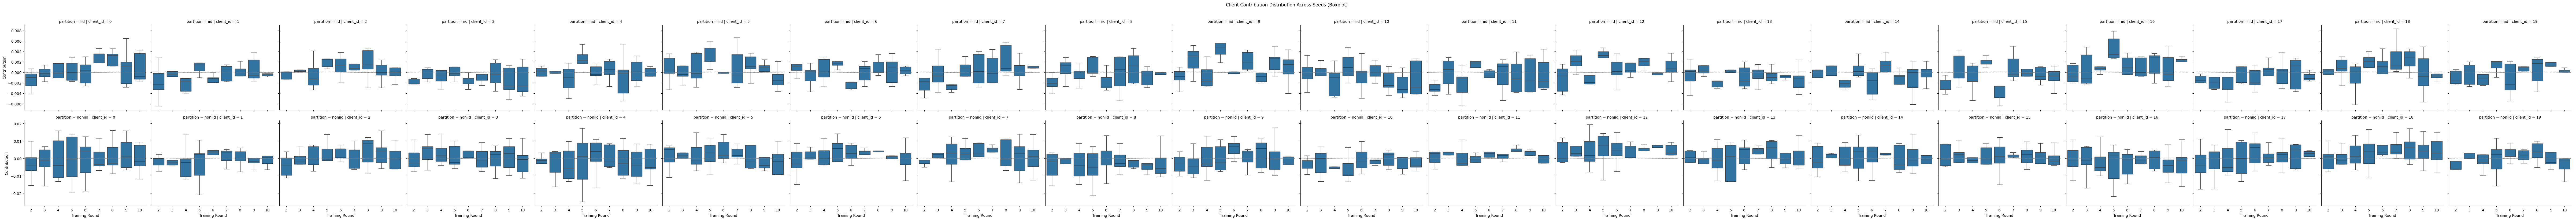

In [ ]:
# Group and filter data
data = cifar_all_20.groupby(['partition', 'client_id', 'round', 'seed'])['contribution'].mean().reset_index()
data = data[data['round'] != 1]


# Create the FacetGrid with boxplots
g = sns.catplot(
    data=data,
    x='round',
    y='contribution',
    col='client_id',
    row='partition',
    kind='box',
    height=4,
    aspect=1.2,
    sharey='row',
    showfliers=False,  # Hide outliers if too noisy
)

# Set axis labels and title
g.set_axis_labels("Training Round", "Contribution")
g.fig.suptitle("Client Contribution Distribution Across Seeds (Boxplot)", y=1.02)
for ax in g.axes.flat:
    ax.axhline(y=0.0, color='gray', linestyle=':', linewidth=1)


plt.tight_layout()
plt.show()


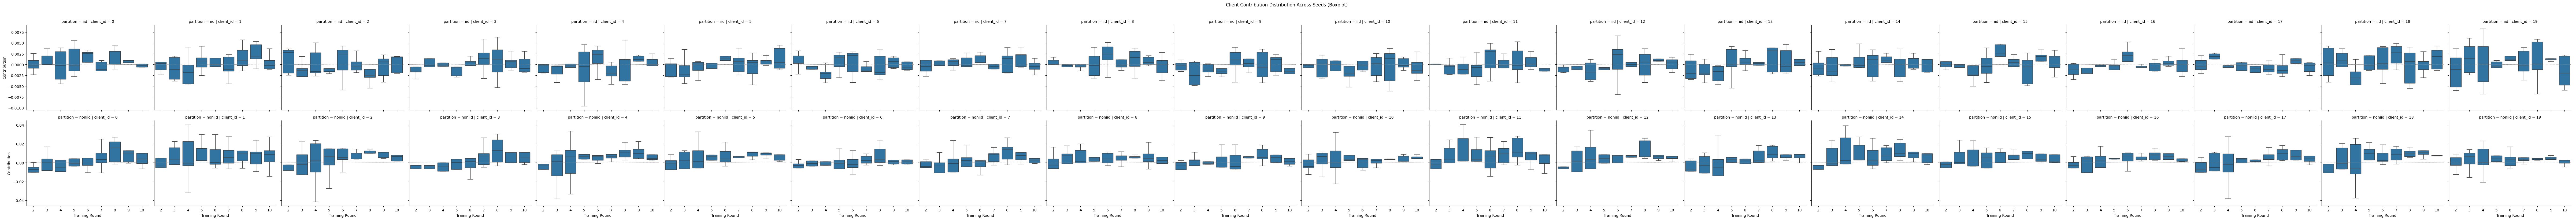

In [ ]:
# Group and filter data
data = imdb_all_20.groupby(['partition', 'client_id', 'round', 'seed'])['contribution'].mean().reset_index()

data = data[(data['round'] >= 2) & (data['round'] <= 10)]

# Create the FacetGrid with boxplots
g = sns.catplot(
    data=data,
    x='round',
    y='contribution',
    col='client_id',
    row='partition',
    kind='box',
    height=4,
    aspect=1.2,
    sharey='row',
    showfliers=False,  # Hide outliers if too noisy
)

# Set axis labels and title
g.set_axis_labels("Training Round", "Contribution")
g.fig.suptitle("Client Contribution Distribution Across Seeds (Boxplot)", y=1.02)
for ax in g.axes.flat:
    ax.axhline(y=0.0, color='gray', linestyle=':', linewidth=1)


plt.tight_layout()
plt.show()
